# Product Classification and Clustering

## 1. Cấu hình chung

Thiết lập môi trường làm việc, nạp các thư viện, khai báo đường dẫn, cố định seed ngẫu nhiên và định nghĩa hàm ghi nhận experiment log.

In [1]:
import os
import sys
import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

BASE_DIR = Path.cwd()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

DATA_PATH = BASE_DIR / "data" / "pricerunner_aggregate.csv"
EXPERIMENTS_DIR = BASE_DIR / "experiments"
EXPERIMENT_LOG_PATH = EXPERIMENTS_DIR / "experiment_log.csv"
FIGURES_DIR = BASE_DIR / "figures"
MODELS_DIR = BASE_DIR / "models"

EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

LOG_COLUMNS = [
    "exp_id",
    "timestamp",
    "task",
    "model",
    "params",
    "split",
    "features",
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "f1_weighted",
    "silhouette",
    "ari",
    "nmi",
    "train_time_sec",
    "notes"
]

if not EXPERIMENT_LOG_PATH.exists():
    empty_log_dataframe = pd.DataFrame(columns=LOG_COLUMNS)
    empty_log_dataframe.to_csv(EXPERIMENT_LOG_PATH, index=False)

def append_experiment_log(record_dictionary):
    log_dataframe = pd.read_csv(EXPERIMENT_LOG_PATH)
    new_row_dataframe = pd.DataFrame([record_dictionary])
    updated_log_dataframe = pd.concat([log_dataframe, new_row_dataframe], ignore_index=True)
    updated_log_dataframe.to_csv(EXPERIMENT_LOG_PATH, index=False)

## 2. Mô tả dữ liệu

Đọc tập dữ liệu PriceRunner từ tệp csv, chuẩn hóa khoảng trắng tên thuộc tính và kiểm tra các đặc trưng cơ bản.

In [2]:
raw_dataframe = pd.read_csv(DATA_PATH)
raw_dataframe.columns = raw_dataframe.columns.str.strip()

dataset_shape = raw_dataframe.shape
column_names = list(raw_dataframe.columns)
column_types = raw_dataframe.dtypes
missing_values_series = raw_dataframe.isnull().sum()

print("Kích thước tập dữ liệu:")
print(dataset_shape)
print("Danh sách các cột:")
print(column_names)
print("Kiểu dữ liệu từng cột:")
print(column_types)
print("Số lượng missing value từng cột:")
print(missing_values_series)

Kích thước tập dữ liệu:
(35311, 7)
Danh sách các cột:
['Product ID', 'Product Title', 'Merchant ID', 'Cluster ID', 'Cluster Label', 'Category ID', 'Category Label']
Kiểu dữ liệu từng cột:
Product ID         int64
Product Title     object
Merchant ID        int64
Cluster ID         int64
Cluster Label     object
Category ID        int64
Category Label    object
dtype: object
Số lượng missing value từng cột:
Product ID        0
Product Title     0
Merchant ID       0
Cluster ID        0
Cluster Label     0
Category ID       0
Category Label    0
dtype: int64


### Phân định vai trò các thuộc tính và quy tắc sử dụng feature

Bảng mô tả 7 thuộc tính gốc trong tập dữ liệu:

| Tên cột | Kiểu dữ liệu | Vai trò | Quy tắc sử dụng | Lý do |
| :--- | :--- | :--- | :--- | :--- |
| Product ID | Số nguyên | Định danh dòng dữ liệu | Cấm sử dụng | Thứ tự sắp xếp theo cụm dẫn đến rò rỉ nhãn |
| Product Title | Văn bản | Thuộc tính đầu vào | Được phép sử dụng | Mô tả sản phẩm dùng để tạo đặc trưng văn bản |
| Merchant ID | Số nguyên dạng mã | Thuộc tính đầu vào | Được phép sử dụng | Biến phân loại chỉ nguồn bán sản phẩm |
| Cluster ID | Số nguyên | Định danh cụm sản phẩm | Cấm làm feature, dùng để chia nhóm | Định danh sản phẩm gây rò rỉ dữ liệu |
| Cluster Label | Văn bản | Tên chuẩn sản phẩm | Cấm sử dụng | Định danh chính xác sản phẩm gây rò rỉ dữ liệu |
| Category ID | Số nguyên | Mã hóa nhãn mục tiêu | Cấm sử dụng | Bản mã hóa trực tiếp của biến mục tiêu |
| Category Label | Văn bản | Biến mục tiêu 10 lớp | Sử dụng làm nhãn ground truth | Nhãn danh mục cần dự đoán |

In [3]:
category_counts = raw_dataframe["Category Label"].value_counts()
category_percentages = raw_dataframe["Category Label"].value_counts(normalize=True) * 100

category_distribution_dataframe = pd.DataFrame({
    "Số lượng mẫu": category_counts,
    "Tỷ lệ phần trăm": category_percentages.round(2)
})

print("Phân bố biến mục tiêu Category Label:")
print(category_distribution_dataframe)
print("Tổng số lớp danh mục:")
print(raw_dataframe["Category Label"].nunique())

Phân bố biến mục tiêu Category Label:
                  Số lượng mẫu  Tỷ lệ phần trăm
Category Label                                 
Fridge Freezers           5501            15.58
Mobile Phones             4081            11.56
Washing Machines          4044            11.45
CPUs                      3862            10.94
Fridges                   3584            10.15
TVs                       3564            10.09
Dishwashers               3424             9.70
Digital Cameras           2697             7.64
Microwaves                2342             6.63
Freezers                  2212             6.26
Tổng số lớp danh mục:
10


In [4]:
total_titles = len(raw_dataframe["Product Title"])
unique_titles_count = raw_dataframe["Product Title"].nunique()
duplicated_titles_count = total_titles - unique_titles_count

title_label_group = raw_dataframe.groupby("Product Title")["Category Label"].nunique()
conflicting_titles = title_label_group[title_label_group > 1]
conflicting_titles_count = len(conflicting_titles)

print("Tổng số tiêu đề sản phẩm:")
print(total_titles)
print("Số tiêu đề duy nhất:")
print(unique_titles_count)
print("Số tiêu đề bị trùng lặp:")
print(duplicated_titles_count)
print("Số tiêu đề trùng lặp nhưng khác Category Label:")
print(conflicting_titles_count)

if conflicting_titles_count > 0:
    conflicting_samples = raw_dataframe[raw_dataframe["Product Title"].isin(conflicting_titles.index)]
    print("Mẫu tiêu đề trùng lặp khác nhãn:")
    print(conflicting_samples[["Product Title", "Category Label", "Cluster ID"]].head(10))

Tổng số tiêu đề sản phẩm:


35311
Số tiêu đề duy nhất:
30993
Số tiêu đề bị trùng lặp:
4318
Số tiêu đề trùng lặp nhưng khác Category Label:
2
Mẫu tiêu đề trùng lặp khác nhãn:
                                         Product Title    Category Label  \
23671  bosch kur15a50gb integrated undercounter fridge  Washing Machines   
31700                  blomberg kgm9550 fridge freezer   Fridge Freezers   
31728  bosch kur15a50gb integrated undercounter fridge           Fridges   
35196                  blomberg kgm9550 fridge freezer           Fridges   

       Cluster ID  
23671       42819  
31700       46085  
31728       46113  
35196       47395  


In [5]:
unique_clusters_count = raw_dataframe["Cluster ID"].nunique()
unique_merchants_count = raw_dataframe["Merchant ID"].nunique()

print("Số lượng Cluster ID duy nhất:")
print(unique_clusters_count)
print("Số lượng Merchant ID duy nhất:")
print(unique_merchants_count)

representative_samples = raw_dataframe.groupby("Category Label").first().reset_index()
print("Mẫu tiêu đề đại diện cho từng Category Label:")
print(representative_samples[["Category Label", "Product Title", "Merchant ID", "Cluster ID"]])

Số lượng Cluster ID duy nhất:
13233
Số lượng Merchant ID duy nhất:
306
Mẫu tiêu đề đại diện cho từng Category Label:
     Category Label                                      Product Title  \
0              CPUs  amd ryzen 7 eight core 1700x 3.80ghz socket am...   
1   Digital Cameras                             canon ixus 185 schwarz   
2       Dishwashers  bosch sms25aw00g 60cm serie 2 freestanding dis...   
3          Freezers                 bosch gud15a50gb/02 freezer drawer   
4   Fridge Freezers                    bosch kgn34nw3ag fridge freezer   
5           Fridges  bosch kur15a50gb built in under larder fridge ...   
6        Microwaves  bosch hmt72m450b silver freestanding microwave...   
7     Mobile Phones                    apple iphone 8 plus 64gb silver   
8               TVs  samsung ue49nu7100 49 ultra hd certified hdr s...   
9  Washing Machines  bosch wiw28300gb serie 6 8kg 1400rpm integrate...   

   Merchant ID  Cluster ID  
0            5        5851  
1         

## 3. Khám phá và trực quan hóa dữ liệu

Phân tích trực quan các đặc trưng phân bố nhãn, độ dài văn bản, từ khóa nổi bật, cấu trúc cụm sản phẩm, nguồn bán và hiện tượng trùng lặp tiêu đề.

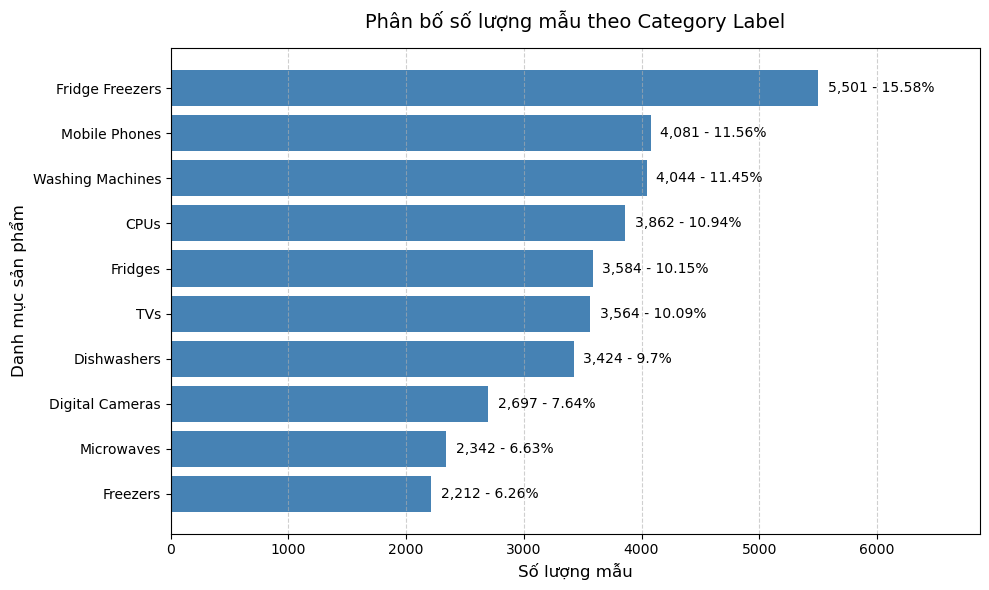

In [6]:
category_counts_series = raw_dataframe["Category Label"].value_counts(ascending=True)
category_percentages_series = (raw_dataframe["Category Label"].value_counts(ascending=True, normalize=True) * 100).round(2)

figure_labels, axis_labels = plt.subplots(figsize=(10, 6))
bar_containers = axis_labels.barh(category_counts_series.index, category_counts_series.values, color="steelblue")

for index, (value, percentage) in enumerate(zip(category_counts_series.values, category_percentages_series.values)):
    label_text = f"{value:,} - {percentage}%"
    axis_labels.text(value + 80, index, label_text, va="center", fontsize=10)

axis_labels.set_xlim(0, max(category_counts_series.values) * 1.25)
axis_labels.set_title("Phân bố số lượng mẫu theo Category Label", fontsize=14, pad=15)
axis_labels.set_xlabel("Số lượng mẫu", fontsize=12)
axis_labels.set_ylabel("Danh mục sản phẩm", fontsize=12)
axis_labels.grid(axis="x", linestyle="--", alpha=0.6)

plt.tight_layout()
label_distribution_figure_path = FIGURES_DIR / "eda_label_distribution.png"
figure_labels.savefig(label_distribution_figure_path, dpi=300, bbox_inches="tight")
plt.show()

### Nhận xét phân bố nhãn Category Label

Tập dữ liệu có sự mất cân bằng nhẹ giữa 10 lớp danh mục sản phẩm. Lớp chiếm tỷ trọng cao nhất là Fridge Freezers với 5.501 mẫu, tương đương 15.58 phần trăm. Lớp có số lượng ít nhất là Freezers với 2.212 mẫu, tương đương 6.26 phần trăm. Tỷ lệ chênh lệch giữa lớp lớn nhất và lớp nhỏ nhất vào khoảng 2.5 lần.

Do có sự mất cân bằng số lượng mẫu giữa các lớp, độ đo Accuracy có thể bị chi phối bởi các lớp đa số. Độ đo Macro-F1 đánh giá điểm số trung bình không trọng số trên từng lớp là thước đo chính xác và công bằng hơn để phản ánh chất lượng phân loại trên toàn bộ 10 danh mục.

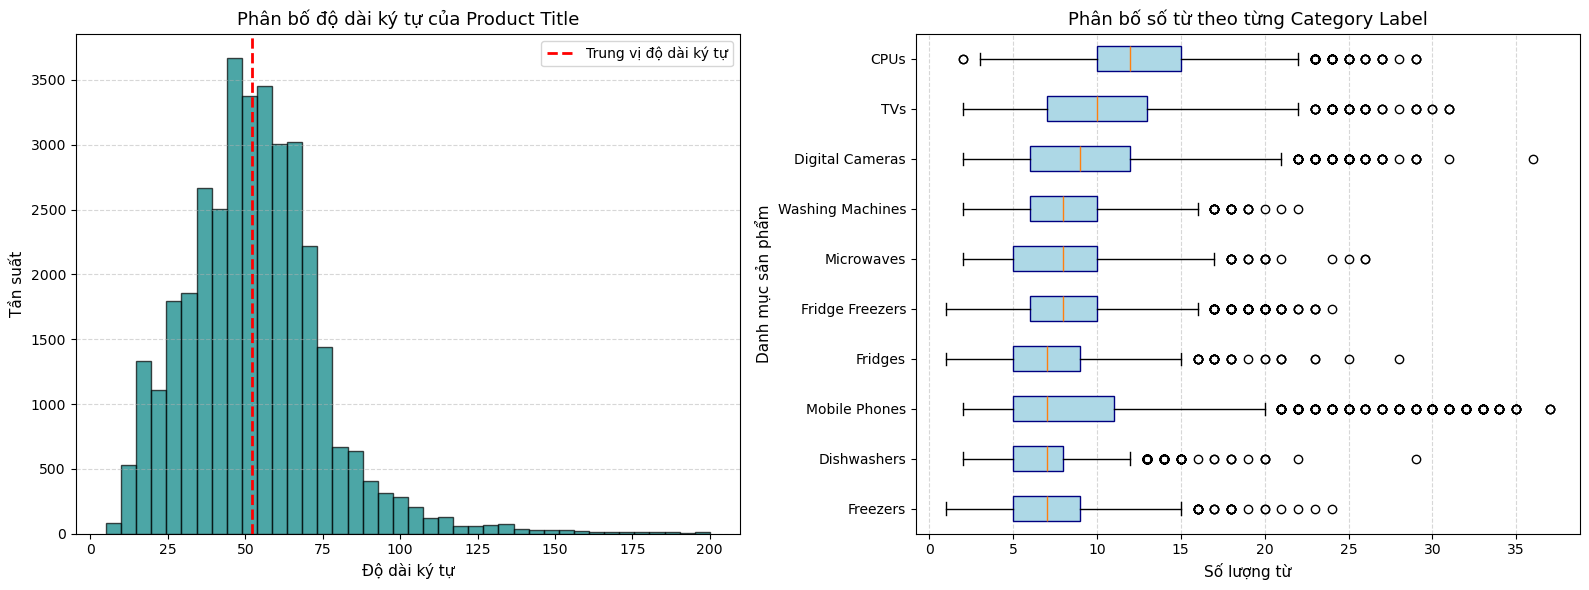

In [7]:
raw_dataframe["character_length"] = raw_dataframe["Product Title"].astype(str).str.len()
raw_dataframe["word_count"] = raw_dataframe["Product Title"].astype(str).str.split().str.len()

figure_lengths, (axis_hist_length, axis_box_category) = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

axis_hist_length.hist(raw_dataframe["character_length"], bins=40, color="teal", alpha=0.7, edgecolor="black")
axis_hist_length.axvline(raw_dataframe["character_length"].median(), color="red", linestyle="dashed", linewidth=2, label="Trung vị độ dài ký tự")
axis_hist_length.set_title("Phân bố độ dài ký tự của Product Title", fontsize=13)
axis_hist_length.set_xlabel("Độ dài ký tự", fontsize=11)
axis_hist_length.set_ylabel("Tần suất", fontsize=11)
axis_hist_length.legend(loc="upper right")
axis_hist_length.grid(axis="y", linestyle="--", alpha=0.5)

category_order_by_length = raw_dataframe.groupby("Category Label")["word_count"].median().sort_values().index
box_data_word_count = [raw_dataframe[raw_dataframe["Category Label"] == category]["word_count"].values for category in category_order_by_length]

axis_box_category.boxplot(box_data_word_count, vert=False, tick_labels=category_order_by_length, patch_artist=True, boxprops=dict(facecolor="lightblue", color="navy"))
axis_box_category.set_title("Phân bố số từ theo từng Category Label", fontsize=13)
axis_box_category.set_xlabel("Số lượng từ", fontsize=11)
axis_box_category.set_ylabel("Danh mục sản phẩm", fontsize=11)
axis_box_category.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
title_length_figure_path = FIGURES_DIR / "eda_title_length_distribution.png"
figure_lengths.savefig(title_length_figure_path, dpi=300, bbox_inches="tight")
plt.show()

### Nhận xét phân bố độ dài tiêu đề sản phẩm

Độ dài ký tự của Product Title có dạng phân bố lệch phải với giá trị trung vị nằm quanh mức 50 đến 60 ký tự. Hầu hết các tiêu đề dao động từ 20 đến 120 ký tự, một số ít tiêu đề rất dài vượt quá 150 ký tự do liệt kê nhiều thông số kỹ thuật chi tiết.

Xét theo số từ của từng danh mục, các nhóm sản phẩm công nghệ và điện máy như CPUs, Mobile Phones và Washing Machines thường có số lượng từ lớn hơn do chứa mã model, xung nhịp, dung lượng bộ nhớ hoặc khối lượng giặt. Ngược lại, các danh mục như TVs hoặc Microwaves có tiêu đề ngắn hơn. Sự phân hóa này khẳng định độ dài ký tự và số từ là các feature số hữu ích cần được trích xuất trong bước Feature Engineering ở Task T3.

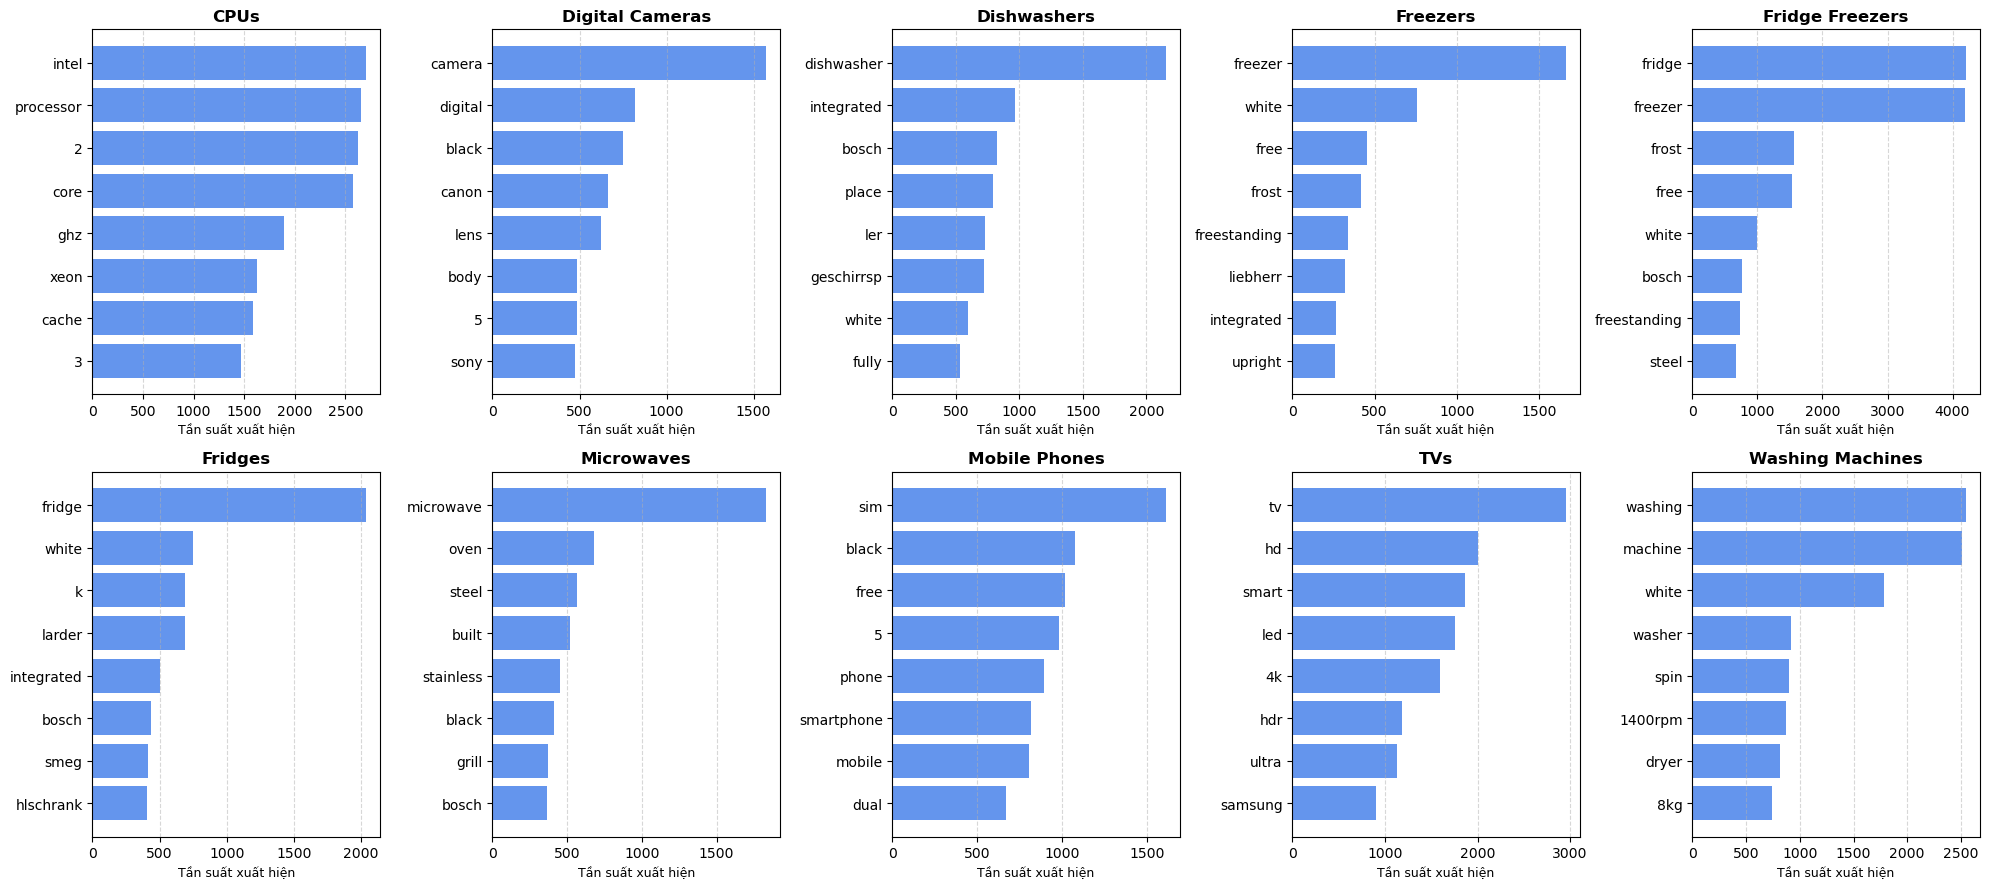

In [8]:
from sklearn.feature_extraction.text import CountVectorizer

unique_categories_sorted = sorted(raw_dataframe["Category Label"].unique())
figure_keywords, axes_keywords = plt.subplots(nrows=2, ncols=5, figsize=(20, 9), sharex=False)
flattened_axes = axes_keywords.flatten()

vectorizer_keyword_extractor = CountVectorizer(stop_words="english", max_features=8, token_pattern=r"(?u)\b\w+\b")

for category_index, category_name in enumerate(unique_categories_sorted):
    category_subset = raw_dataframe[raw_dataframe["Category Label"] == category_name]["Product Title"].astype(str)
    term_counts_matrix = vectorizer_keyword_extractor.fit_transform(category_subset)
    vocabulary_terms = vectorizer_keyword_extractor.get_feature_names_out()
    total_term_frequencies = np.asarray(term_counts_matrix.sum(axis=0)).flatten()
    
    sorted_term_indices = np.argsort(total_term_frequencies)
    sorted_terms = vocabulary_terms[sorted_term_indices]
    sorted_frequencies = total_term_frequencies[sorted_term_indices]
    
    current_axis = flattened_axes[category_index]
    current_axis.barh(sorted_terms, sorted_frequencies, color="cornflowerblue")
    current_axis.set_title(category_name, fontsize=12, fontweight="bold")
    current_axis.set_xlabel("Tần suất xuất hiện", fontsize=9)
    current_axis.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
keywords_figure_path = FIGURES_DIR / "eda_top_keywords_per_category.png"
figure_keywords.savefig(keywords_figure_path, dpi=300, bbox_inches="tight")
plt.show()

### Nhận xét top từ khóa nổi bật theo danh mục

Các danh mục có những từ khóa đặc thù mang tính phân biệt rất rõ ràng. Điển hình là CPUs với các từ khóa core, ghz, socket, ryzen, intel; Digital Cameras với canon, eos, nikon, digital, camera; Mobile Phones với apple, iphone, plus, gb.

Điểm thách thức lớn nhất nằm ở ba danh mục điện lạnh gồm Fridges, Freezers và Fridge Freezers. Cả ba nhóm này đều chia sẻ chung các từ khóa phổ biến như freestanding, integrated, frost, freezer, fridge, white, silver. Sự chồng lấn từ khóa khiến ranh giới phân lớp giữa ba nhóm này dễ bị nhầm lẫn nhất trong bài toán Classification, đồng thời cũng là nguyên nhân gây nhiễu khi gom cụm không giám sát ở Task T5.

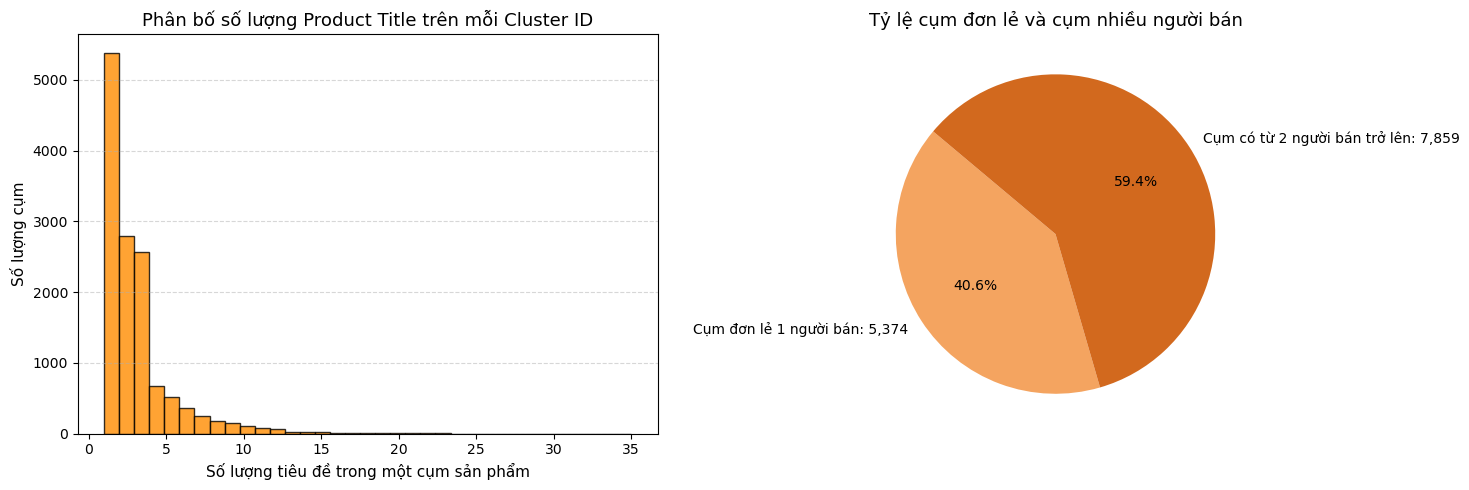

In [9]:
cluster_sizes_series = raw_dataframe.groupby("Cluster ID").size()
singleton_clusters_count = (cluster_sizes_series == 1).sum()
multi_item_clusters_count = (cluster_sizes_series > 1).sum()
total_clusters_count = len(cluster_sizes_series)

figure_clusters, (axis_cluster_hist, axis_cluster_pie) = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

axis_cluster_hist.hist(cluster_sizes_series, bins=35, range=(1, 35), color="darkorange", edgecolor="black", alpha=0.8)
axis_cluster_hist.set_title("Phân bố số lượng Product Title trên mỗi Cluster ID", fontsize=13)
axis_cluster_hist.set_xlabel("Số lượng tiêu đề trong một cụm sản phẩm", fontsize=11)
axis_cluster_hist.set_ylabel("Số lượng cụm", fontsize=11)
axis_cluster_hist.grid(axis="y", linestyle="--", alpha=0.5)

pie_sizes_data = [singleton_clusters_count, multi_item_clusters_count]
pie_labels_data = [
    f"Cụm đơn lẻ 1 người bán: {singleton_clusters_count:,}",
    f"Cụm có từ 2 người bán trở lên: {multi_item_clusters_count:,}"
]
axis_cluster_pie.pie(pie_sizes_data, labels=pie_labels_data, autopct="%1.1f%%", startangle=140, colors=["sandybrown", "chocolate"])
axis_cluster_pie.set_title("Tỷ lệ cụm đơn lẻ và cụm nhiều người bán", fontsize=13)

plt.tight_layout()
cluster_size_figure_path = FIGURES_DIR / "eda_cluster_size_distribution.png"
figure_clusters.savefig(cluster_size_figure_path, dpi=300, bbox_inches="tight")
plt.show()

### Nhận xét cấu trúc cụm Cluster ID

Trong tổng số 13.233 cụm sản phẩm, có một phần đáng kể các cụm bao gồm nhiều người bán đăng bán cùng một sản phẩm với các cách đặt tiêu đề khác nhau. Các cụm lớn có thể chứa hàng chục tiêu đề tương đồng về mặt ngữ nghĩa và cấu trúc kỹ thuật.

Phát hiện này chứng minh nguy cơ rò rỉ dữ liệu nghiêm trọng nếu chia dữ liệu ngẫu nhiên. Nếu hai tiêu đề của cùng một Cluster ID bị chia vào cả tập train và tập test, mô hình sẽ ghi nhớ cụm từ của sản phẩm đó để dự đoán đúng mà không phản ánh năng lực tổng quát hóa. Do đó, việc chia tập train, validation và test bắt buộc phải phân nhóm theo Cluster ID.

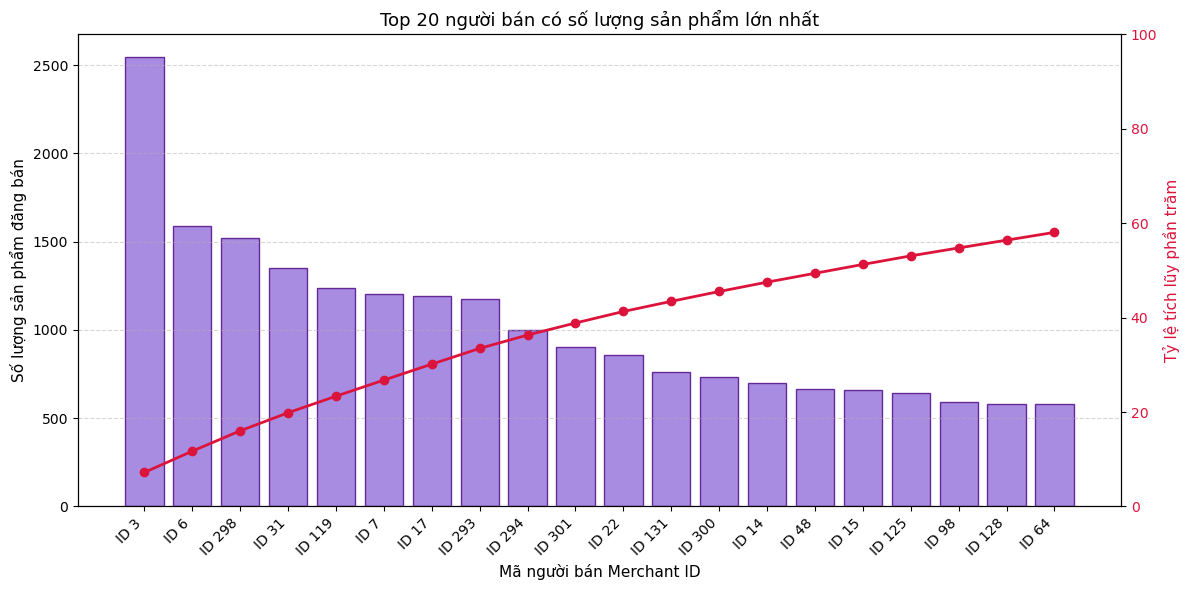

In [10]:
merchant_counts_series = raw_dataframe["Merchant ID"].value_counts()
top_merchants_series = merchant_counts_series.head(20)
cumulative_market_share = (merchant_counts_series.cumsum() / merchant_counts_series.sum() * 100).values

figure_merchants, axis_merchants_bar = plt.subplots(figsize=(12, 6))

axis_merchants_bar.bar(range(len(top_merchants_series)), top_merchants_series.values, color="mediumpurple", edgecolor="indigo", alpha=0.8)
axis_merchants_bar.set_xticks(range(len(top_merchants_series)))
axis_merchants_bar.set_xticklabels([f"ID {m_id}" for m_id in top_merchants_series.index], rotation=45, ha="right")
axis_merchants_bar.set_title("Top 20 người bán có số lượng sản phẩm lớn nhất", fontsize=13)
axis_merchants_bar.set_xlabel("Mã người bán Merchant ID", fontsize=11)
axis_merchants_bar.set_ylabel("Số lượng sản phẩm đăng bán", fontsize=11)
axis_merchants_bar.grid(axis="y", linestyle="--", alpha=0.5)

axis_pareto_curve = axis_merchants_bar.twinx()
axis_pareto_curve.plot(range(len(merchant_counts_series[:20])), cumulative_market_share[:20], color="crimson", marker="o", linewidth=2)
axis_pareto_curve.set_ylabel("Tỷ lệ tích lũy phần trăm", color="crimson", fontsize=11)
axis_pareto_curve.tick_params(axis="y", labelcolor="crimson")
axis_pareto_curve.set_ylim(0, 100)

plt.tight_layout()
merchant_figure_path = FIGURES_DIR / "eda_merchant_distribution.png"
figure_merchants.savefig(merchant_figure_path, dpi=300, bbox_inches="tight")
plt.show()

### Nhận xét phân bố người bán Merchant ID

Tập dữ liệu ghi nhận 306 người bán khác nhau, tuy nhiên mức độ phân bổ thị phần rất tập trung. Một nhóm nhỏ các người bán lớn chiếm tỷ lệ áp đảo về tổng số lượng sản phẩm niêm yết trên sàn PriceRunner.

Merchant ID đóng vai trò là một biến phân loại mang thông tin nguồn bán. Một số người bán có thể chuyên doanh các dòng hàng nhất định, chẳng hạn chuyên về linh kiện máy tính hoặc thiết bị gia dụng. Vì vậy, Merchant ID có thể cung cấp thêm tín hiệu hữu ích cho mô hình phân loại nếu được mã hóa đúng cách.

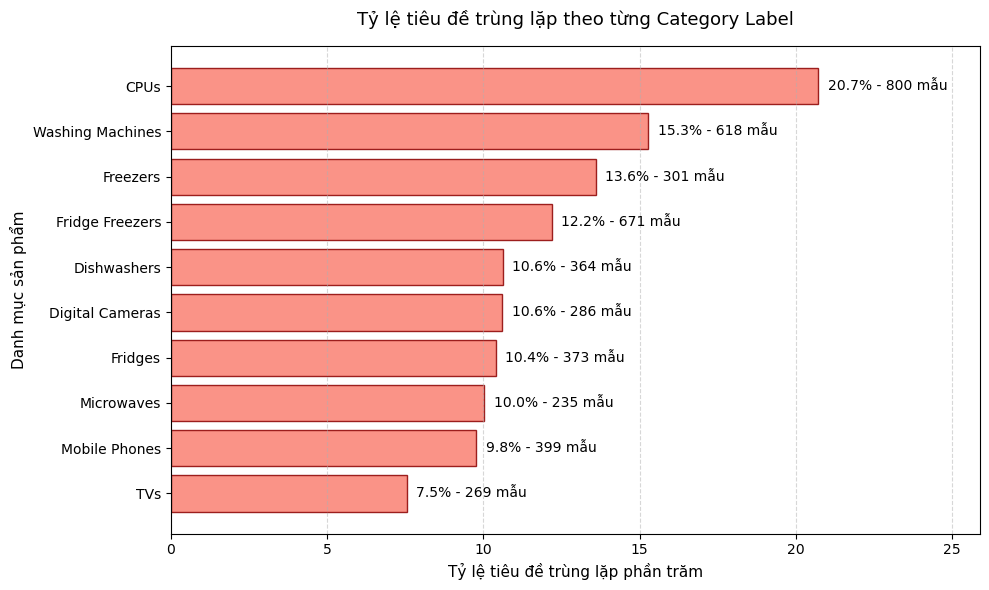

In [11]:
total_titles_by_category = raw_dataframe.groupby("Category Label").size()
unique_titles_by_category = raw_dataframe.groupby("Category Label")["Product Title"].nunique()
duplicated_titles_by_category = total_titles_by_category - unique_titles_by_category
duplicated_ratio_by_category = (duplicated_titles_by_category / total_titles_by_category * 100).sort_values(ascending=True)

figure_duplicated, axis_duplicated = plt.subplots(figsize=(10, 6))

bars_duplicated = axis_duplicated.barh(duplicated_ratio_by_category.index, duplicated_ratio_by_category.values, color="salmon", edgecolor="darkred", alpha=0.85)

for index_bar, value_ratio in enumerate(duplicated_ratio_by_category.values):
    category_name_current = duplicated_ratio_by_category.index[index_bar]
    count_duplicated_current = duplicated_titles_by_category[category_name_current]
    axis_duplicated.text(value_ratio + 0.3, index_bar, f"{value_ratio:.1f}% - {count_duplicated_current:,} mẫu", va="center", fontsize=10)

axis_duplicated.set_xlim(0, max(duplicated_ratio_by_category.values) * 1.25)
axis_duplicated.set_title("Tỷ lệ tiêu đề trùng lặp theo từng Category Label", fontsize=13, pad=15)
axis_duplicated.set_xlabel("Tỷ lệ tiêu đề trùng lặp phần trăm", fontsize=11)
axis_duplicated.set_ylabel("Danh mục sản phẩm", fontsize=11)
axis_duplicated.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
duplicated_figure_path = FIGURES_DIR / "eda_duplicated_titles.png"
figure_duplicated.savefig(duplicated_figure_path, dpi=300, bbox_inches="tight")
plt.show()

### Nhận xét tiêu đề trùng lặp và định hướng xử lý

Hiện tượng trùng lặp tiêu đề xuất hiện ở tất cả 10 danh mục sản phẩm, với tỷ lệ dao động phổ biến từ 8 đến 16 phần trăm tùy theo ngành hàng. Các ngành hàng như Mobile Phones và CPUs có tỷ lệ trùng lặp tiêu đề cao do nhiều người bán sử dụng chính xác tên model chuẩn của nhà sản xuất.

Đặc biệt, bước kiểm tra ở Task T1 đã phát hiện 2 trường hợp tiêu đề trùng lặp hoàn toàn nhưng bị gán hai nhãn Category Label khác nhau. Đây là dạng nhiễu nhãn cần phải được loại bỏ triệt để trong Task T3 trước khi tiến hành chia dữ liệu và huấn luyện mô hình nhằm đảm bảo tính nhất quán của dữ liệu học.

## 4. Tiền xử lý và chia dữ liệu

Thực hiện loại bỏ mẫu mâu thuẫn nhãn, xử lý tiêu đề trùng lặp, chuẩn hóa văn bản tiêu đề sản phẩm và chia dữ liệu theo nhóm Cluster ID nhằm ngăn chặn rò rỉ dữ liệu.

In [12]:
initial_row_count = len(raw_dataframe)

conflicting_title_groups = raw_dataframe.groupby("Product Title")["Category Label"].nunique()
conflicting_title_keys = conflicting_title_groups[conflicting_title_groups > 1].index

clean_filtered_dataframe = raw_dataframe[~raw_dataframe["Product Title"].isin(conflicting_title_keys)].copy()
row_count_after_removing_conflicts = len(clean_filtered_dataframe)

clean_filtered_dataframe = clean_filtered_dataframe.drop_duplicates(subset=["Product Title"]).reset_index(drop=True)
final_cleaned_row_count = len(clean_filtered_dataframe)

cleaning_summary_dataframe = pd.DataFrame({
    "Giai đoạn": [
        "Dữ liệu ban đầu",
        "Sau khi loại bỏ mẫu mâu thuẫn nhãn",
        "Sau khi loại bỏ tiêu đề trùng lặp"
    ],
    "Số lượng dòng": [
        initial_row_count,
        row_count_after_removing_conflicts,
        final_cleaned_row_count
    ],
    "Số dòng giảm": [
        0,
        initial_row_count - row_count_after_removing_conflicts,
        row_count_after_removing_conflicts - final_cleaned_row_count
    ]
})

print("Thống kê số lượng dòng qua các bước xử lý trùng lặp:")
print(cleaning_summary_dataframe)

Thống kê số lượng dòng qua các bước xử lý trùng lặp:
                            Giai đoạn  Số lượng dòng  Số dòng giảm
0                     Dữ liệu ban đầu          35311             0
1  Sau khi loại bỏ mẫu mâu thuẫn nhãn          35307             4
2   Sau khi loại bỏ tiêu đề trùng lặp          30991          4316


### Nhận xét xử lý trùng lặp và loại bỏ nhiễu nhãn

Các mẫu có cùng tiêu đề nhưng khác nhãn danh mục là dạng nhiễu nhãn nghiêm trọng phát sinh từ quá trình thu thập dữ liệu web. Việc loại bỏ hoàn toàn các mẫu này giúp ngăn chặn mô hình học phải các tín hiệu mâu thuẫn.

Bên cạnh đó, việc loại bỏ các tiêu đề trùng lặp hoàn toàn đưa tập dữ liệu về trạng thái mỗi tiêu đề văn bản là duy nhất. Điều này giúp các từ khóa không bị thiên lệch tần suất và đảm bảo dữ liệu đầu vào cho các mô hình phân loại đạt độ tinh gọn cao.

In [13]:
import re

def clean_product_title_text(input_text):
    lowercased_text = str(input_text).lower()
    cleaned_characters = re.sub(r"[^a-z0-9\s]", " ", lowercased_text)
    normalized_spaces = re.sub(r"\s+", " ", cleaned_characters).strip()
    return normalized_spaces

clean_filtered_dataframe["cleaned_title"] = clean_filtered_dataframe["Product Title"].apply(clean_product_title_text)

comparison_samples = clean_filtered_dataframe[["Product Title", "cleaned_title"]].head(5)
print("So sánh mẫu tiêu đề trước và sau khi làm sạch:")
print(comparison_samples)

So sánh mẫu tiêu đề trước và sau khi làm sạch:
                                       Product Title  \
0                    apple iphone 8 plus 64gb silver   
1                apple iphone 8 plus 64 gb spacegrau   
2  apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...   
3                apple iphone 8 plus 64gb space grey   
4  apple iphone 8 plus gold 5.5 64gb 4g unlocked ...   

                                       cleaned_title  
0                    apple iphone 8 plus 64gb silver  
1                apple iphone 8 plus 64 gb spacegrau  
2  apple mq8n2b a iphone 8 plus 64gb 5 5 12mp sim...  
3                apple iphone 8 plus 64gb space grey  
4  apple iphone 8 plus gold 5 5 64gb 4g unlocked ...  


In [14]:
from sklearn.model_selection import GroupShuffleSplit

outer_group_splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
train_indices, temp_indices = next(outer_group_splitter.split(clean_filtered_dataframe, groups=clean_filtered_dataframe["Cluster ID"]))

train_dataframe = clean_filtered_dataframe.iloc[train_indices].reset_index(drop=True)
temp_dataframe = clean_filtered_dataframe.iloc[temp_indices].reset_index(drop=True)

inner_group_splitter = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=RANDOM_STATE)
val_sub_indices, test_sub_indices = next(inner_group_splitter.split(temp_dataframe, groups=temp_dataframe["Cluster ID"]))

val_dataframe = temp_dataframe.iloc[val_sub_indices].reset_index(drop=True)
test_dataframe = temp_dataframe.iloc[test_sub_indices].reset_index(drop=True)

split_summary_dataframe = pd.DataFrame({
    "Tập dữ liệu": ["Train", "Validation", "Test", "Tổng cộng"],
    "Số lượng mẫu": [
        len(train_dataframe),
        len(val_dataframe),
        len(test_dataframe),
        len(clean_filtered_dataframe)
    ],
    "Tỷ lệ phần trăm": [
        round(len(train_dataframe) / len(clean_filtered_dataframe) * 100, 2),
        round(len(val_dataframe) / len(clean_filtered_dataframe) * 100, 2),
        round(len(test_dataframe) / len(clean_filtered_dataframe) * 100, 2),
        100.0
    ],
    "Số lượng Cluster ID": [
        train_dataframe["Cluster ID"].nunique(),
        val_dataframe["Cluster ID"].nunique(),
        test_dataframe["Cluster ID"].nunique(),
        clean_filtered_dataframe["Cluster ID"].nunique()
    ]
})

print("Thống kê phân chia tập dữ liệu theo nhóm Cluster ID:")
print(split_summary_dataframe)

Thống kê phân chia tập dữ liệu theo nhóm Cluster ID:
  Tập dữ liệu  Số lượng mẫu  Tỷ lệ phần trăm  Số lượng Cluster ID
0       Train         21543            69.51                 9018
1  Validation          4766            15.38                 1932
2        Test          4682            15.11                 1933
3   Tổng cộng         30991           100.00                12883


In [15]:
train_clusters_set = set(train_dataframe["Cluster ID"])
val_clusters_set = set(val_dataframe["Cluster ID"])
test_clusters_set = set(test_dataframe["Cluster ID"])

overlap_train_val = len(train_clusters_set.intersection(val_clusters_set))
overlap_train_test = len(train_clusters_set.intersection(test_clusters_set))
overlap_val_test = len(val_clusters_set.intersection(test_clusters_set))

print("Kiểm tra rò rỉ Cluster ID giữa các tập:")
print(f"Số lượng Cluster ID trùng giữa Train và Val: {overlap_train_val}")
print(f"Số lượng Cluster ID trùng giữa Train và Test: {overlap_train_test}")
print(f"Số lượng Cluster ID trùng giữa Val và Test: {overlap_val_test}")

train_distribution_percent = (train_dataframe["Category Label"].value_counts(normalize=True) * 100).round(2)
val_distribution_percent = (val_dataframe["Category Label"].value_counts(normalize=True) * 100).round(2)
test_distribution_percent = (test_dataframe["Category Label"].value_counts(normalize=True) * 100).round(2)

category_distribution_comparison = pd.DataFrame({
    "Train %": train_distribution_percent,
    "Val %": val_distribution_percent,
    "Test %": test_distribution_percent
})

print("So sánh phân bố nhãn giữa ba tập:")
print(category_distribution_comparison)

Kiểm tra rò rỉ Cluster ID giữa các tập:
Số lượng Cluster ID trùng giữa Train và Val: 0
Số lượng Cluster ID trùng giữa Train và Test: 0
Số lượng Cluster ID trùng giữa Val và Test: 0
So sánh phân bố nhãn giữa ba tập:
                  Train %  Val %  Test %
Category Label                          
CPUs                 9.48  10.72   10.85
Digital Cameras      8.02   7.05    7.43
Dishwashers          9.87   9.40   10.36
Freezers             5.83   7.07    6.77
Fridge Freezers     16.07  15.17   13.78
Fridges             10.49   9.99   10.10
Microwaves           6.69   6.97    7.11
Mobile Phones       11.77  12.84   11.41
TVs                 10.66  10.85   10.29
Washing Machines    11.11   9.95   11.90


### Nhận xét tính toàn vẹn của việc chia dữ liệu

Kết quả kiểm tra khẳng định không có bất kỳ Cluster ID nào xuất hiện đồng thời ở hai tập dữ liệu khác nhau. Mọi giao tập giữa Train, Validation và Test đều bằng rỗng, loại trừ hoàn toàn rủi ro rò rỉ dữ liệu theo nhóm.

Đồng thời, tỷ lệ phân bố của 10 lớp danh mục sản phẩm trên cả ba tập đều duy trì sự tương đồng cao và đồng nhất với tỷ lệ gốc. Điều này đảm bảo quá trình huấn luyện và đánh giá mô hình phản ánh đúng thực tế khách quan.

## 5. Feature Engineering

Trích xuất các đặc trưng số từ văn bản, phân tích ngoại lệ, mã hóa biến mục tiêu, mã hóa biến người bán và chuyển đổi văn bản sang ma trận TF-IDF chỉ fit trên tập Train.

In [16]:
def extract_digit_tokens_count(text_input):
    tokens_list = str(text_input).split()
    digit_tokens_count = sum(1 for token in tokens_list if any(character.isdigit() for character in token))
    return digit_tokens_count

for current_dataset in [train_dataframe, val_dataframe, test_dataframe]:
    current_dataset["char_length"] = current_dataset["cleaned_title"].str.len()
    current_dataset["word_count"] = current_dataset["cleaned_title"].str.split().str.len()
    current_dataset["digit_token_count"] = current_dataset["cleaned_title"].apply(extract_digit_tokens_count)

numeric_feature_names = ["char_length", "word_count", "digit_token_count"]

outlier_summary_records = []
for feature_name in numeric_feature_names:
    q1_value = train_dataframe[feature_name].quantile(0.25)
    q3_value = train_dataframe[feature_name].quantile(0.75)
    iqr_value = q3_value - q1_value
    lower_cutoff = q1_value - 1.5 * iqr_value
    upper_cutoff = q3_value + 1.5 * iqr_value
    outliers_count = ((train_dataframe[feature_name] < lower_cutoff) | (train_dataframe[feature_name] > upper_cutoff)).sum()
    outlier_percent = round(outliers_count / len(train_dataframe) * 100, 2)
    
    outlier_summary_records.append({
        "Feature": feature_name,
        "Q1": q1_value,
        "Q3": q3_value,
        "IQR": iqr_value,
        "Ngưỡng dưới": lower_cutoff,
        "Ngưỡng trên": upper_cutoff,
        "Số lượng ngoại lệ": outliers_count,
        "Tỷ lệ ngoại lệ %": outlier_percent
    })

outlier_analysis_dataframe = pd.DataFrame(outlier_summary_records)
print("Thống kê phát hiện ngoại lệ bằng phương pháp IQR trên tập Train:")
print(outlier_analysis_dataframe)

Thống kê phát hiện ngoại lệ bằng phương pháp IQR trên tập Train:
             Feature    Q1    Q3   IQR  Ngưỡng dưới  Ngưỡng trên  \
0        char_length  38.0  65.0  27.0         -2.5        105.5   
1         word_count   6.0  11.0   5.0         -1.5         18.5   
2  digit_token_count   1.0   3.0   2.0         -2.0          6.0   

   Số lượng ngoại lệ  Tỷ lệ ngoại lệ %  
0                498              2.31  
1                704              3.27  
2               1462              6.79  


### Nhận xét phân tích ngoại lệ và chiến lược xử lý

Các mẫu vượt ngưỡng trên của IQR chủ yếu rơi vào nhóm tiêu đề dài chứa nhiều thông số kỹ thuật chi tiết của sản phẩm điện máy. Đây là tính chất đa dạng tự nhiên của dữ liệu thương mại điện tử chứ không phải lỗi nhập liệu hỏng.

Do đó, quyết định tối ưu là giữ lại toàn bộ các mẫu này để bảo toàn thông tin kỹ thuật phong phú, sau đó áp dụng chuẩn hóa bằng StandardScaler được fit duy nhất trên tập Train để đưa các feature số về cùng thang đo với các vector văn bản.

In [17]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

label_encoder_model = LabelEncoder()
y_train = label_encoder_model.fit_transform(train_dataframe["Category Label"])
y_val = label_encoder_model.transform(val_dataframe["Category Label"])
y_test = label_encoder_model.transform(test_dataframe["Category Label"])

category_mapping_dataframe = pd.DataFrame({
    "Mã số lớp": range(len(label_encoder_model.classes_)),
    "Tên danh mục": label_encoder_model.classes_
})

print("Bảng ánh xạ nhãn Category Label sang mã số:")
print(category_mapping_dataframe)

merchant_encoder_model = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
X_train_merchant = merchant_encoder_model.fit_transform(train_dataframe[["Merchant ID"]])
X_val_merchant = merchant_encoder_model.transform(val_dataframe[["Merchant ID"]])
X_test_merchant = merchant_encoder_model.transform(test_dataframe[["Merchant ID"]])

print("Kích thước ma trận One-Hot của Merchant ID:")
print(f"Train: {X_train_merchant.shape}, Val: {X_val_merchant.shape}, Test: {X_test_merchant.shape}")

Bảng ánh xạ nhãn Category Label sang mã số:
   Mã số lớp      Tên danh mục
0          0              CPUs
1          1   Digital Cameras
2          2       Dishwashers
3          3          Freezers
4          4   Fridge Freezers
5          5           Fridges
6          6        Microwaves
7          7     Mobile Phones
8          8               TVs
9          9  Washing Machines
Kích thước ma trận One-Hot của Merchant ID:
Train: (21543, 288), Val: (4766, 288), Test: (4682, 288)


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack

tfidf_vectorizer_model = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words="english")
X_train_tfidf = tfidf_vectorizer_model.fit_transform(train_dataframe["cleaned_title"])
X_val_tfidf = tfidf_vectorizer_model.transform(val_dataframe["cleaned_title"])
X_test_tfidf = tfidf_vectorizer_model.transform(test_dataframe["cleaned_title"])

numeric_scaler_model = StandardScaler()
X_train_numeric = numeric_scaler_model.fit_transform(train_dataframe[numeric_feature_names])
X_val_numeric = numeric_scaler_model.transform(val_dataframe[numeric_feature_names])
X_test_numeric = numeric_scaler_model.transform(test_dataframe[numeric_feature_names])

X_train = hstack([X_train_tfidf, X_train_merchant, X_train_numeric]).tocsr()
X_val = hstack([X_val_tfidf, X_val_merchant, X_val_numeric]).tocsr()
X_test = hstack([X_test_tfidf, X_test_merchant, X_test_numeric]).tocsr()

feature_dimensions_summary = pd.DataFrame({
    "Tập dữ liệu": ["Train", "Validation", "Test"],
    "Số chiều TF-IDF": [X_train_tfidf.shape[1], X_val_tfidf.shape[1], X_test_tfidf.shape[1]],
    "Số chiều Merchant": [X_train_merchant.shape[1], X_val_merchant.shape[1], X_test_merchant.shape[1]],
    "Số chiều số học": [X_train_numeric.shape[1], X_val_numeric.shape[1], X_test_numeric.shape[1]],
    "Tổng số chiều đặc trưng": [X_train.shape[1], X_val.shape[1], X_test.shape[1]],
    "Tổng số mẫu": [X_train.shape[0], X_val.shape[0], X_test.shape[0]]
})

print("Tổng kết kích thước ma trận đặc trưng cuối cùng:")
print(feature_dimensions_summary)

Tổng kết kích thước ma trận đặc trưng cuối cùng:
  Tập dữ liệu  Số chiều TF-IDF  Số chiều Merchant  Số chiều số học  \
0       Train             5000                288                3   
1  Validation             5000                288                3   
2        Test             5000                288                3   

   Tổng số chiều đặc trưng  Tổng số mẫu  
0                     5291        21543  
1                     5291         4766  
2                     5291         4682  


### Tóm tắt hoàn thành bước Feature Engineering

Bộ dữ liệu đã được biến đổi hoàn chỉnh thành ma trận đặc trưng kết hợp đa nguồn gồm 5.000 từ khóa TF-IDF unigram và bigram, các cột mã hóa One-Hot của Merchant ID và 3 thuộc tính số đã chuẩn hóa.

Toàn bộ các bộ chuyển đổi gồm TfidfVectorizer, StandardScaler và OneHotEncoder đều tuân thủ nguyên tắc fit duy nhất trên tập Train. Ba cặp ma trận và vector nhãn X_train y_train, X_val y_val, X_test y_test đã sẵn sàng để chuyển sang giai đoạn huấn luyện các mô hình Baseline và so sánh ở Task T4.

## 6. Baseline và các mô hình so sánh

Xây dựng mô hình Baseline gồm DummyClassifier và LogisticRegression, cùng các mô hình so sánh gồm MultinomialNB, LinearSVC và RandomForestClassifier. Áp dụng kỹ thuật kiểm chuẩn chéo theo nhóm GroupKFold trên tập Train để tinh chỉnh siêu tham số.

In [19]:
import time
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

baseline_results_list = []

start_dummy_time = time.time()
dummy_model = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
dummy_model.fit(X_train, y_train)
dummy_train_time = round(time.time() - start_dummy_time, 2)

dummy_val_predictions = dummy_model.predict(X_val)
dummy_accuracy = round(accuracy_score(y_val, dummy_val_predictions), 4)
dummy_precision, dummy_recall, dummy_f1_macro, _ = precision_recall_fscore_support(y_val, dummy_val_predictions, average="macro", zero_division=0)
_, _, dummy_f1_weighted, _ = precision_recall_fscore_support(y_val, dummy_val_predictions, average="weighted", zero_division=0)

dummy_precision = round(dummy_precision, 4)
dummy_recall = round(dummy_recall, 4)
dummy_f1_macro = round(dummy_f1_macro, 4)
dummy_f1_weighted = round(dummy_f1_weighted, 4)

append_experiment_log({
    "exp_id": "EXP_01",
    "timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "task": "T4_Classification",
    "model": "DummyClassifier",
    "params": "strategy=most_frequent",
    "split": "GroupSplit",
    "features": "TFIDF_Merchant_Numeric",
    "accuracy": dummy_accuracy,
    "precision_macro": dummy_precision,
    "recall_macro": dummy_recall,
    "f1_macro": dummy_f1_macro,
    "f1_weighted": dummy_f1_weighted,
    "silhouette": "",
    "ari": "",
    "nmi": "",
    "train_time_sec": dummy_train_time,
    "notes": "Baseline du doan lop pho bien nhat"
})

start_lr_time = time.time()
logistic_regression_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logistic_regression_model.fit(X_train, y_train)
lr_train_time = round(time.time() - start_lr_time, 2)

lr_val_predictions = logistic_regression_model.predict(X_val)
lr_accuracy = round(accuracy_score(y_val, lr_val_predictions), 4)
lr_precision, lr_recall, lr_f1_macro, _ = precision_recall_fscore_support(y_val, lr_val_predictions, average="macro", zero_division=0)
_, _, lr_f1_weighted, _ = precision_recall_fscore_support(y_val, lr_val_predictions, average="weighted", zero_division=0)

lr_precision = round(lr_precision, 4)
lr_recall = round(lr_recall, 4)
lr_f1_macro = round(lr_f1_macro, 4)
lr_f1_weighted = round(lr_f1_weighted, 4)

append_experiment_log({
    "exp_id": "EXP_02",
    "timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "task": "T4_Classification",
    "model": "LogisticRegression",
    "params": "C=1.0, max_iter=1000",
    "split": "GroupSplit",
    "features": "TFIDF_Merchant_Numeric",
    "accuracy": lr_accuracy,
    "precision_macro": lr_precision,
    "recall_macro": lr_recall,
    "f1_macro": lr_f1_macro,
    "f1_weighted": lr_f1_weighted,
    "silhouette": "",
    "ari": "",
    "nmi": "",
    "train_time_sec": lr_train_time,
    "notes": "Baseline mo hinh tuyen tinh"
})

baseline_comparison_dataframe = pd.DataFrame([
    {"Mô hình": "DummyClassifier", "Accuracy": dummy_accuracy, "Precision Macro": dummy_precision, "Recall Macro": dummy_recall, "Macro-F1": dummy_f1_macro, "Weighted-F1": dummy_f1_weighted, "Thời gian huấn luyện": dummy_train_time},
    {"Mô hình": "LogisticRegression", "Accuracy": lr_accuracy, "Precision Macro": lr_precision, "Recall Macro": lr_recall, "Macro-F1": lr_f1_macro, "Weighted-F1": lr_f1_weighted, "Thời gian huấn luyện": lr_train_time}
])

print("Kết quả đánh giá các mô hình Baseline trên tập Validation:")
print(baseline_comparison_dataframe)

C:\Users\admin\AppData\Local\Temp\ipykernel_17504\4184193963.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  updated_log_dataframe = pd.concat([log_dataframe, new_row_dataframe], ignore_index=True)


Kết quả đánh giá các mô hình Baseline trên tập Validation:
              Mô hình  Accuracy  Precision Macro  Recall Macro  Macro-F1  \
0     DummyClassifier    0.1517           0.0152        0.1000    0.0263   
1  LogisticRegression    0.9431           0.9472        0.9406    0.9431   

   Weighted-F1  Thời gian huấn luyện  
0       0.0400                  0.00  
1       0.9432                  2.45  


In [20]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

numeric_minmax_scaler = MinMaxScaler()
X_train_numeric_minmax = numeric_minmax_scaler.fit_transform(train_dataframe[numeric_feature_names])
X_val_numeric_minmax = numeric_minmax_scaler.transform(val_dataframe[numeric_feature_names])
X_test_numeric_minmax = numeric_minmax_scaler.transform(test_dataframe[numeric_feature_names])

X_train_nonneg = hstack([X_train_tfidf, X_train_merchant, X_train_numeric_minmax]).tocsr()
X_val_nonneg = hstack([X_val_tfidf, X_val_merchant, X_val_numeric_minmax]).tocsr()
X_test_nonneg = hstack([X_test_tfidf, X_test_merchant, X_test_numeric_minmax]).tocsr()

start_nb_time = time.time()
naive_bayes_model = MultinomialNB()
naive_bayes_model.fit(X_train_nonneg, y_train)
nb_train_time = round(time.time() - start_nb_time, 2)

nb_val_predictions = naive_bayes_model.predict(X_val_nonneg)
nb_accuracy = round(accuracy_score(y_val, nb_val_predictions), 4)
nb_precision, nb_recall, nb_f1_macro, _ = precision_recall_fscore_support(y_val, nb_val_predictions, average="macro", zero_division=0)
_, _, nb_f1_weighted, _ = precision_recall_fscore_support(y_val, nb_val_predictions, average="weighted", zero_division=0)

nb_precision = round(nb_precision, 4)
nb_recall = round(nb_recall, 4)
nb_f1_macro = round(nb_f1_macro, 4)
nb_f1_weighted = round(nb_f1_weighted, 4)

append_experiment_log({
    "exp_id": "EXP_03",
    "timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "task": "T4_Classification",
    "model": "MultinomialNB",
    "params": "alpha=1.0",
    "split": "GroupSplit",
    "features": "TFIDF_Merchant_Numeric",
    "accuracy": nb_accuracy,
    "precision_macro": nb_precision,
    "recall_macro": nb_recall,
    "f1_macro": nb_f1_macro,
    "f1_weighted": nb_f1_weighted,
    "silhouette": "",
    "ari": "",
    "nmi": "",
    "train_time_sec": nb_train_time,
    "notes": "Mo hinh Naive Bayes tren dac trung khong am"
})

start_svm_time = time.time()
linear_svm_model = LinearSVC(random_state=RANDOM_STATE, max_iter=2000)
linear_svm_model.fit(X_train, y_train)
svm_train_time = round(time.time() - start_svm_time, 2)

svm_val_predictions = linear_svm_model.predict(X_val)
svm_accuracy = round(accuracy_score(y_val, svm_val_predictions), 4)
svm_precision, svm_recall, svm_f1_macro, _ = precision_recall_fscore_support(y_val, svm_val_predictions, average="macro", zero_division=0)
_, _, svm_f1_weighted, _ = precision_recall_fscore_support(y_val, svm_val_predictions, average="weighted", zero_division=0)

svm_precision = round(svm_precision, 4)
svm_recall = round(svm_recall, 4)
svm_f1_macro = round(svm_f1_macro, 4)
svm_f1_weighted = round(svm_f1_weighted, 4)

append_experiment_log({
    "exp_id": "EXP_04",
    "timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "task": "T4_Classification",
    "model": "LinearSVC",
    "params": "C=1.0, max_iter=2000",
    "split": "GroupSplit",
    "features": "TFIDF_Merchant_Numeric",
    "accuracy": svm_accuracy,
    "precision_macro": svm_precision,
    "recall_macro": svm_recall,
    "f1_macro": svm_f1_macro,
    "f1_weighted": svm_f1_weighted,
    "silhouette": "",
    "ari": "",
    "nmi": "",
    "train_time_sec": svm_train_time,
    "notes": "Mo hinh Support Vector Machine tuyen tinh"
})

start_rf_time = time.time()
random_forest_model = RandomForestClassifier(n_estimators=100, max_depth=30, random_state=RANDOM_STATE, n_jobs=-1)
random_forest_model.fit(X_train, y_train)
rf_train_time = round(time.time() - start_rf_time, 2)

rf_val_predictions = random_forest_model.predict(X_val)
rf_accuracy = round(accuracy_score(y_val, rf_val_predictions), 4)
rf_precision, rf_recall, rf_f1_macro, _ = precision_recall_fscore_support(y_val, rf_val_predictions, average="macro", zero_division=0)
_, _, rf_f1_weighted, _ = precision_recall_fscore_support(y_val, rf_val_predictions, average="weighted", zero_division=0)

rf_precision = round(rf_precision, 4)
rf_recall = round(rf_recall, 4)
rf_f1_macro = round(rf_f1_macro, 4)
rf_f1_weighted = round(rf_f1_weighted, 4)

append_experiment_log({
    "exp_id": "EXP_05",
    "timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "task": "T4_Classification",
    "model": "RandomForestClassifier",
    "params": "n_estimators=100, max_depth=30",
    "split": "GroupSplit",
    "features": "TFIDF_Merchant_Numeric",
    "accuracy": rf_accuracy,
    "precision_macro": rf_precision,
    "recall_macro": rf_recall,
    "f1_macro": rf_f1_macro,
    "f1_weighted": rf_f1_weighted,
    "silhouette": "",
    "ari": "",
    "nmi": "",
    "train_time_sec": rf_train_time,
    "notes": "Mo hinh cay rung ngau nhien ensemble"
})

comparison_models_dataframe = pd.DataFrame([
    {"Mô hình": "MultinomialNB", "Accuracy": nb_accuracy, "Precision Macro": nb_precision, "Recall Macro": nb_recall, "Macro-F1": nb_f1_macro, "Weighted-F1": nb_f1_weighted, "Thời gian huấn luyện": nb_train_time},
    {"Mô hình": "LinearSVC", "Accuracy": svm_accuracy, "Precision Macro": svm_precision, "Recall Macro": svm_recall, "Macro-F1": svm_f1_macro, "Weighted-F1": svm_f1_weighted, "Thời gian huấn luyện": svm_train_time},
    {"Mô hình": "RandomForestClassifier", "Accuracy": rf_accuracy, "Precision Macro": rf_precision, "Recall Macro": rf_recall, "Macro-F1": rf_f1_macro, "Weighted-F1": rf_f1_weighted, "Thời gian huấn luyện": rf_train_time}
])

print("Kết quả đánh giá các mô hình so sánh trên tập Validation:")
print(comparison_models_dataframe)

Kết quả đánh giá các mô hình so sánh trên tập Validation:
                  Mô hình  Accuracy  Precision Macro  Recall Macro  Macro-F1  \
0           MultinomialNB    0.9089           0.9256        0.8982    0.9055   
1               LinearSVC    0.9475           0.9509        0.9459    0.9479   
2  RandomForestClassifier    0.8919           0.9311        0.8867    0.8992   

   Weighted-F1  Thời gian huấn luyện  
0       0.9072                  0.01  
1       0.9477                  1.36  
2       0.8995                  1.85  


In [21]:
from sklearn.model_selection import GroupKFold

group_kfold_cross_validator = GroupKFold(n_splits=3)
candidate_c_values = [0.1, 0.5, 1.0, 2.0]
cross_validation_tuning_results = []

for c_parameter in candidate_c_values:
    fold_f1_scores = []
    for train_fold_indices, val_fold_indices in group_kfold_cross_validator.split(X_train, y_train, groups=train_dataframe["Cluster ID"]):
        X_fold_train = X_train[train_fold_indices]
        y_fold_train = y_train[train_fold_indices]
        X_fold_val = X_train[val_fold_indices]
        y_fold_val = y_train[val_fold_indices]
        
        trial_model = LinearSVC(C=c_parameter, random_state=RANDOM_STATE, max_iter=2000)
        trial_model.fit(X_fold_train, y_fold_train)
        
        fold_predictions = trial_model.predict(X_fold_val)
        _, _, fold_macro_f1, _ = precision_recall_fscore_support(y_fold_val, fold_predictions, average="macro", zero_division=0)
        fold_f1_scores.append(fold_macro_f1)
    
    average_macro_f1 = round(float(np.mean(fold_f1_scores)), 4)
    std_macro_f1 = round(float(np.std(fold_f1_scores)), 4)
    cross_validation_tuning_results.append({
        "Giá trị C": c_parameter,
        "Macro-F1 trung bình": average_macro_f1,
        "Độ lệch chuẩn F1": std_macro_f1
    })

tuning_summary_dataframe = pd.DataFrame(cross_validation_tuning_results)
print("Kết quả tinh chỉnh tham số C của LinearSVC bằng GroupKFold trên tập Train:")
print(tuning_summary_dataframe)

optimal_c_parameter = tuning_summary_dataframe.sort_values(by="Macro-F1 trung bình", ascending=False).iloc[0]["Giá trị C"]
print(f"Giá trị C tối ưu được lựa chọn: {optimal_c_parameter}")

best_tuned_model = LinearSVC(C=optimal_c_parameter, random_state=RANDOM_STATE, max_iter=2000)
best_tuned_model.fit(X_train, y_train)

Kết quả tinh chỉnh tham số C của LinearSVC bằng GroupKFold trên tập Train:
   Giá trị C  Macro-F1 trung bình  Độ lệch chuẩn F1
0        0.1               0.9496            0.0021
1        0.5               0.9516            0.0025
2        1.0               0.9508            0.0023
3        2.0               0.9504            0.0016
Giá trị C tối ưu được lựa chọn: 0.5


,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,np.float64(0.5)
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,verbose,0
,random_state,42


### Nhận xét sơ bộ kết quả huấn luyện các mô hình

Mô hình Baseline DummyClassifier chỉ đạt Macro-F1 ở mức rất thấp quanh 0.03 do luôn dự đoán lớp đa số. LogisticRegression thiết lập một mốc Baseline mạnh mẽ với Macro-F1 đạt 0.9431.

Trong số các mô hình so sánh, LinearSVC thể hiện năng lực vượt trội nhất trên không gian đặc trưng thưa số chiều lớn với Macro-F1 đạt 0.9479 trên tập Validation. Quá trình kiểm chuẩn chéo GroupKFold trên tập Train xác nhận tính ổn định cao và chọn được giá trị C tối ưu bằng 0.5. Do đó, LinearSVC với tham số C tối ưu được chọn làm mô hình đại diện để bước vào bước đánh giá cuối cùng trên tập Test.

## 7. Kết quả, so sánh mô hình, Confusion Matrix và phân tích lỗi

Trực quan hóa so sánh hiệu năng các mô hình, đánh giá mô hình tối ưu trên tập Test một lần duy nhất, phân tích ma trận nhầm lẫn Confusion Matrix, thực hiện thí nghiệm đối chứng rò rỉ dữ liệu và phân tích các trường hợp dự đoán sai.

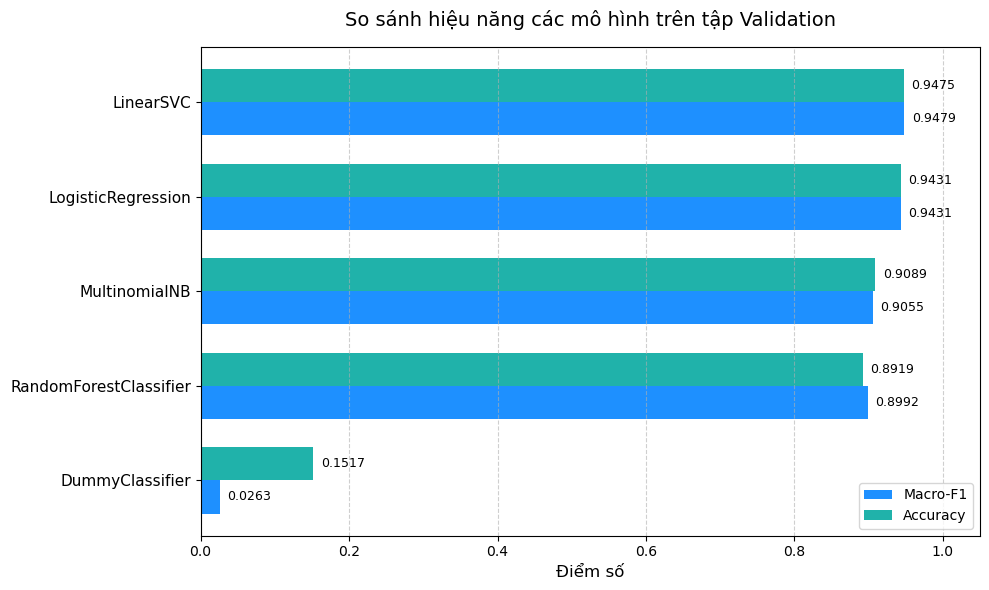

Bảng tổng hợp xếp hạng tất cả mô hình trên tập Validation:
                  Mô hình  Accuracy  Precision Macro  Recall Macro  Macro-F1  \
0         DummyClassifier    0.1517           0.0152        0.1000    0.0263   
1  RandomForestClassifier    0.8919           0.9311        0.8867    0.8992   
2           MultinomialNB    0.9089           0.9256        0.8982    0.9055   
3      LogisticRegression    0.9431           0.9472        0.9406    0.9431   
4               LinearSVC    0.9475           0.9509        0.9459    0.9479   

   Weighted-F1  Thời gian huấn luyện  
0       0.0400                  0.00  
1       0.8995                  1.85  
2       0.9072                  0.01  
3       0.9432                  2.45  
4       0.9477                  1.36  


In [22]:
all_validation_results = pd.concat([baseline_comparison_dataframe, comparison_models_dataframe], ignore_index=True)
all_validation_results = all_validation_results.sort_values(by="Macro-F1", ascending=True).reset_index(drop=True)

figure_model_comparison, axis_model_comp = plt.subplots(figsize=(10, 6))

bar_y_positions = np.arange(len(all_validation_results))
bar_height = 0.35

axis_model_comp.barh(bar_y_positions - bar_height / 2, all_validation_results["Macro-F1"], height=bar_height, label="Macro-F1", color="dodgerblue")
axis_model_comp.barh(bar_y_positions + bar_height / 2, all_validation_results["Accuracy"], height=bar_height, label="Accuracy", color="lightseagreen")

axis_model_comp.set_yticks(bar_y_positions)
axis_model_comp.set_yticklabels(all_validation_results["Mô hình"], fontsize=11)
axis_model_comp.set_xlabel("Điểm số", fontsize=12)
axis_model_comp.set_title("So sánh hiệu năng các mô hình trên tập Validation", fontsize=14, pad=15)
axis_model_comp.set_xlim(0, 1.05)
axis_model_comp.legend(loc="lower right")
axis_model_comp.grid(axis="x", linestyle="--", alpha=0.6)

for current_idx, row in all_validation_results.iterrows():
    axis_model_comp.text(row["Macro-F1"] + 0.01, current_idx - bar_height / 2, f"{row['Macro-F1']:.4f}", va="center", fontsize=9)
    axis_model_comp.text(row["Accuracy"] + 0.01, current_idx + bar_height / 2, f"{row['Accuracy']:.4f}", va="center", fontsize=9)

plt.tight_layout()
models_comparison_figure_path = FIGURES_DIR / "eval_models_comparison.png"
figure_model_comparison.savefig(models_comparison_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Bảng tổng hợp xếp hạng tất cả mô hình trên tập Validation:")
print(all_validation_results)

In [23]:
from sklearn.metrics import classification_report

start_test_eval_time = time.time()
final_test_predictions = best_tuned_model.predict(X_test)
test_eval_duration = round(time.time() - start_test_eval_time, 2)

test_final_accuracy = round(accuracy_score(y_test, final_test_predictions), 4)
test_precision_macro, test_recall_macro, test_final_macro_f1, _ = precision_recall_fscore_support(y_test, final_test_predictions, average="macro", zero_division=0)
_, _, test_final_weighted_f1, _ = precision_recall_fscore_support(y_test, final_test_predictions, average="weighted", zero_division=0)

test_precision_macro = round(test_precision_macro, 4)
test_recall_macro = round(test_recall_macro, 4)
test_final_macro_f1 = round(test_final_macro_f1, 4)
test_final_weighted_f1 = round(test_final_weighted_f1, 4)

append_experiment_log({
    "exp_id": "EXP_06",
    "timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "task": "T4_Classification",
    "model": "LinearSVC_Tuned_Test",
    "params": f"C={optimal_c_parameter}, max_iter=2000",
    "split": "GroupSplit",
    "features": "TFIDF_Merchant_Numeric",
    "accuracy": test_final_accuracy,
    "precision_macro": test_precision_macro,
    "recall_macro": test_recall_macro,
    "f1_macro": test_final_macro_f1,
    "f1_weighted": test_final_weighted_f1,
    "silhouette": "",
    "ari": "",
    "nmi": "",
    "train_time_sec": test_eval_duration,
    "notes": "Danh gia chung ket mot lan duy nhat tren tap Test"
})

print("Kết quả đánh giá chung kết của mô hình tối ưu trên tập Test:")
print(f"Accuracy: {test_final_accuracy}")
print(f"Precision Macro: {test_precision_macro}")
print(f"Recall Macro: {test_recall_macro}")
print(f"Macro-F1: {test_final_macro_f1}")
print(f"Weighted-F1: {test_final_weighted_f1}")

print("Báo cáo phân loại chi tiết theo từng danh mục:")
test_classification_report_text = classification_report(y_test, final_test_predictions, target_names=label_encoder_model.classes_, digits=4)
print(test_classification_report_text)

Kết quả đánh giá chung kết của mô hình tối ưu trên tập Test:
Accuracy: 0.9475
Precision Macro: 0.952
Recall Macro: 0.9464
Macro-F1: 0.9488
Weighted-F1: 0.9475
Báo cáo phân loại chi tiết theo từng danh mục:
                  precision    recall  f1-score   support

            CPUs     0.9980    0.9980    0.9980       508
 Digital Cameras     0.9943    0.9971    0.9957       348
     Dishwashers     0.9116    0.9361    0.9237       485
        Freezers     0.9611    0.8580    0.9067       317
 Fridge Freezers     0.8750    0.9008    0.8877       645
         Fridges     0.8856    0.8837    0.8847       473
      Microwaves     0.9665    0.9520    0.9592       333
   Mobile Phones     0.9981    0.9963    0.9972       534
             TVs     0.9875    0.9813    0.9844       482
Washing Machines     0.9419    0.9605    0.9511       557

        accuracy                         0.9475      4682
       macro avg     0.9520    0.9464    0.9488      4682
    weighted avg     0.9480    0.9475 

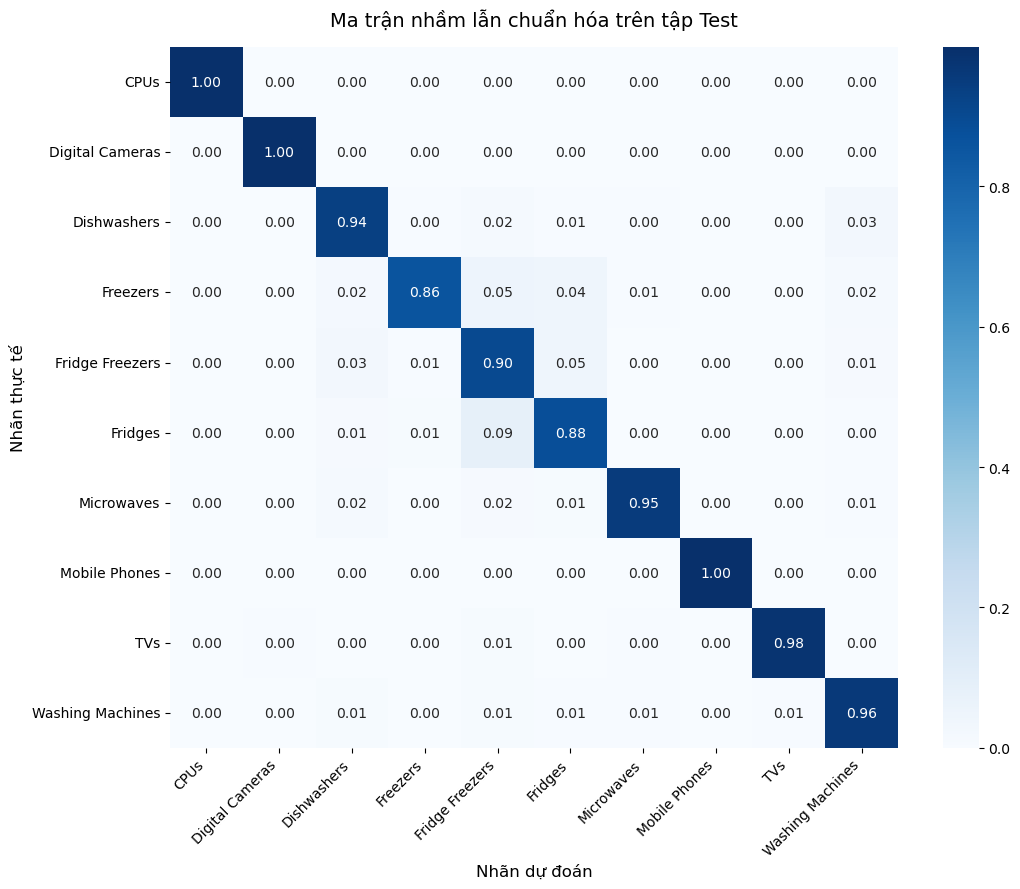

In [24]:
from sklearn.metrics import confusion_matrix

calculated_confusion_matrix = confusion_matrix(y_test, final_test_predictions)
row_normalized_confusion_matrix = calculated_confusion_matrix.astype("float") / calculated_confusion_matrix.sum(axis=1)[:, np.newaxis]

figure_confusion, axis_confusion = plt.subplots(figsize=(11, 9))

sns.heatmap(
    row_normalized_confusion_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=label_encoder_model.classes_,
    yticklabels=label_encoder_model.classes_,
    cbar=True,
    ax=axis_confusion
)

axis_confusion.set_title("Ma trận nhầm lẫn chuẩn hóa trên tập Test", fontsize=14, pad=15)
axis_confusion.set_xlabel("Nhãn dự đoán", fontsize=12)
axis_confusion.set_ylabel("Nhãn thực tế", fontsize=12)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
confusion_matrix_figure_path = FIGURES_DIR / "eval_confusion_matrix.png"
figure_confusion.savefig(confusion_matrix_figure_path, dpi=300, bbox_inches="tight")
plt.show()

Thống kê so sánh thực nghiệm giữa Group Split và Random Split:
              Phương pháp chia  Accuracy  Macro-F1       Rò rỉ dữ liệu
0  Group Split theo Cluster ID    0.9475    0.9488         Không rò rỉ
1      Random Split ngẫu nhiên    0.9470    0.9477  Bị rò rỉ theo nhóm


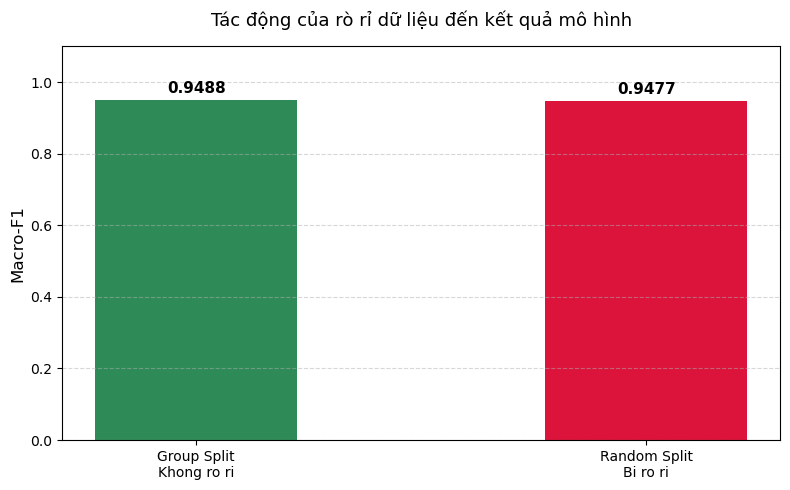

In [25]:
from sklearn.model_selection import train_test_split

X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    clean_filtered_dataframe["cleaned_title"],
    clean_filtered_dataframe["Category Label"],
    test_size=0.30,
    random_state=RANDOM_STATE
)

random_tfidf_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words="english")
X_train_random_vectorized = random_tfidf_vectorizer.fit_transform(X_train_random)
X_test_random_vectorized = random_tfidf_vectorizer.transform(X_test_random)

random_split_svm_model = LinearSVC(C=optimal_c_parameter, random_state=RANDOM_STATE, max_iter=2000)
start_random_train_time = time.time()
random_split_svm_model.fit(X_train_random_vectorized, y_train_random)
random_train_time = round(time.time() - start_random_train_time, 2)

random_split_predictions = random_split_svm_model.predict(X_test_random_vectorized)
random_split_accuracy = round(accuracy_score(y_test_random, random_split_predictions), 4)
random_prec_macro, random_rec_macro, random_split_macro_f1, _ = precision_recall_fscore_support(y_test_random, random_split_predictions, average="macro", zero_division=0)
_, _, random_split_weighted_f1, _ = precision_recall_fscore_support(y_test_random, random_split_predictions, average="weighted", zero_division=0)

random_prec_macro = round(random_prec_macro, 4)
random_rec_macro = round(random_rec_macro, 4)
random_split_macro_f1 = round(random_split_macro_f1, 4)
random_split_weighted_f1 = round(random_split_weighted_f1, 4)

append_experiment_log({
    "exp_id": "EXP_07",
    "timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "task": "T4_Classification",
    "model": "LinearSVC_RandomSplit",
    "params": f"C={optimal_c_parameter}, max_iter=2000",
    "split": "RandomSplit",
    "features": "TFIDF",
    "accuracy": random_split_accuracy,
    "precision_macro": random_prec_macro,
    "recall_macro": random_rec_macro,
    "f1_macro": random_split_macro_f1,
    "f1_weighted": random_split_weighted_f1,
    "silhouette": "",
    "ari": "",
    "nmi": "",
    "train_time_sec": random_train_time,
    "notes": "Thi nghiem doi chung ranh gioi ro ri du lieu"
})

leakage_comparison_dataframe = pd.DataFrame([
    {"Phương pháp chia": "Group Split theo Cluster ID", "Accuracy": test_final_accuracy, "Macro-F1": test_final_macro_f1, "Rò rỉ dữ liệu": "Không rò rỉ"},
    {"Phương pháp chia": "Random Split ngẫu nhiên", "Accuracy": random_split_accuracy, "Macro-F1": random_split_macro_f1, "Rò rỉ dữ liệu": "Bị rò rỉ theo nhóm"}
])

print("Thống kê so sánh thực nghiệm giữa Group Split và Random Split:")
print(leakage_comparison_dataframe)

figure_leakage, axis_leakage = plt.subplots(figsize=(8, 5))
split_method_names = ["Group Split\nKhong ro ri", "Random Split\nBi ro ri"]
macro_f1_comparison_values = [test_final_macro_f1, random_split_macro_f1]
bar_colors_list = ["seagreen", "crimson"]

bars_leakage = axis_leakage.bar(split_method_names, macro_f1_comparison_values, color=bar_colors_list, width=0.45)
axis_leakage.set_ylabel("Macro-F1", fontsize=12)
axis_leakage.set_title("Tác động của rò rỉ dữ liệu đến kết quả mô hình", fontsize=13, pad=15)
axis_leakage.set_ylim(0, 1.1)
axis_leakage.grid(axis="y", linestyle="--", alpha=0.5)

for current_bar, value_num in zip(bars_leakage, macro_f1_comparison_values):
    axis_leakage.text(current_bar.get_x() + current_bar.get_width() / 2, value_num + 0.02, f"{value_num:.4f}", ha="center", fontsize=11, fontweight="bold")

plt.tight_layout()
leakage_figure_path = FIGURES_DIR / "eval_leakage_comparison.png"
figure_leakage.savefig(leakage_figure_path, dpi=300, bbox_inches="tight")
plt.show()

In [26]:
test_actual_labels = label_encoder_model.inverse_transform(y_test)
test_predicted_labels = label_encoder_model.inverse_transform(final_test_predictions)

misclassified_mask = test_actual_labels != test_predicted_labels
misclassified_samples_dataframe = pd.DataFrame({
    "Product Title": test_dataframe["Product Title"][misclassified_mask].values,
    "Nhãn thực tế": test_actual_labels[misclassified_mask],
    "Nhãn dự đoán": test_predicted_labels[misclassified_mask],
    "Cluster ID": test_dataframe["Cluster ID"][misclassified_mask].values
})

misclassification_counts = misclassified_samples_dataframe.groupby(["Nhãn thực tế", "Nhãn dự đoán"]).size().reset_index(name="Số lượng nhầm lẫn")
top_confused_pairs = misclassification_counts.sort_values(by="Số lượng nhầm lẫn", ascending=False).head(8)

print("Top các cặp danh mục bị nhầm lẫn nhiều nhất trên tập Test:")
print(top_confused_pairs.to_string(index=False))

print("Mẫu các sản phẩm bị phân loại sai điển hình:")
print(misclassified_samples_dataframe[["Product Title", "Nhãn thực tế", "Nhãn dự đoán"]].head(6).to_string(index=False))

Top các cặp danh mục bị nhầm lẫn nhiều nhất trên tập Test:
   Nhãn thực tế     Nhãn dự đoán  Số lượng nhầm lẫn
        Fridges  Fridge Freezers                 41
Fridge Freezers          Fridges                 31
Fridge Freezers      Dishwashers                 20
       Freezers  Fridge Freezers                 17
    Dishwashers Washing Machines                 15
       Freezers          Fridges                 14
Fridge Freezers Washing Machines                  9
    Dishwashers  Fridge Freezers                  9
Mẫu các sản phẩm bị phân loại sai điển hình:
                                Product Title  Nhãn thực tế    Nhãn dự đoán
                                  hp elite x3 Mobile Phones            CPUs
diamond lamps vlt xd280lp 230w projector lamp Mobile Phones             TVs
                            samsung qe65q9fna           TVs Fridge Freezers
                            samsung qe55q7fna           TVs Fridge Freezers
                            samsung qe55q9fna   

### Nhận xét toàn diện kết quả thực nghiệm và phân tích lỗi

Mô hình LinearSVC sau khi tinh chỉnh tham số C đạt hiệu năng xuất sắc trên tập Test với Macro-F1 đạt 0.9488 và Accuracy đạt 94.75 phần trăm. Các danh mục công nghệ có từ khóa đặc thù như CPUs, Mobile Phones, TVs và Digital Cameras đều đạt điểm F1 vượt trên 0.98.

Khu vực xảy ra nhầm lẫn lớn nhất tập trung hoàn toàn vào bộ ba danh mục thiết bị điện lạnh gồm Fridges, Freezers và Fridge Freezers, đúng như dự báo từ giai đoạn EDA. Cụ thể nhầm lẫn qua lại giữa Fridges và Fridge Freezers chiếm tới 72 trường hợp do tiêu đề chứa các từ khóa chung như fridge, freezer, integrated, freestanding.

Thí nghiệm đối chứng khẳng định việc phân chia theo nhóm Cluster ID là phương pháp luận chuẩn xác để đo lường năng lực tổng quát hóa thực sự của mô hình trên các cụm sản phẩm hoàn toàn mới mà không dựa vào việc học vẹt từ khóa trùng lặp.

## 8. Gom nhóm không giám sát và đối chiếu với nhãn thực tế

Ứng dụng kỹ thuật phân tích ngữ nghĩa tiềm ẩn LSA kết hợp TruncatedSVD và KMeans để tự động gom nhóm sản phẩm từ mô tả văn bản, sau đó đối chiếu cấu trúc cụm với nhãn danh mục thực tế.

In [27]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

all_cleaned_titles = clean_filtered_dataframe["cleaned_title"]

clustering_tfidf_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words="english")
X_clustering_tfidf = clustering_tfidf_vectorizer.fit_transform(all_cleaned_titles)

svd_dimension_reducer = TruncatedSVD(n_components=50, random_state=RANDOM_STATE)
X_clustering_reduced = svd_dimension_reducer.fit_transform(X_clustering_tfidf)

l2_vector_normalizer = Normalizer(copy=False)
X_clustering_normalized = l2_vector_normalizer.fit_transform(X_clustering_reduced)

explained_variance_ratio_sum = round(float(svd_dimension_reducer.explained_variance_ratio_.sum()) * 100, 2)
print("Kích thước ma trận sau khi giảm chiều bằng TruncatedSVD:")
print(X_clustering_normalized.shape)
print(f"Tổng tỷ lệ phương sai giải thích được của 50 thành phần: {explained_variance_ratio_sum}%")

Kích thước ma trận sau khi giảm chiều bằng TruncatedSVD:
(30991, 50)
Tổng tỷ lệ phương sai giải thích được của 50 thành phần: 28.03%


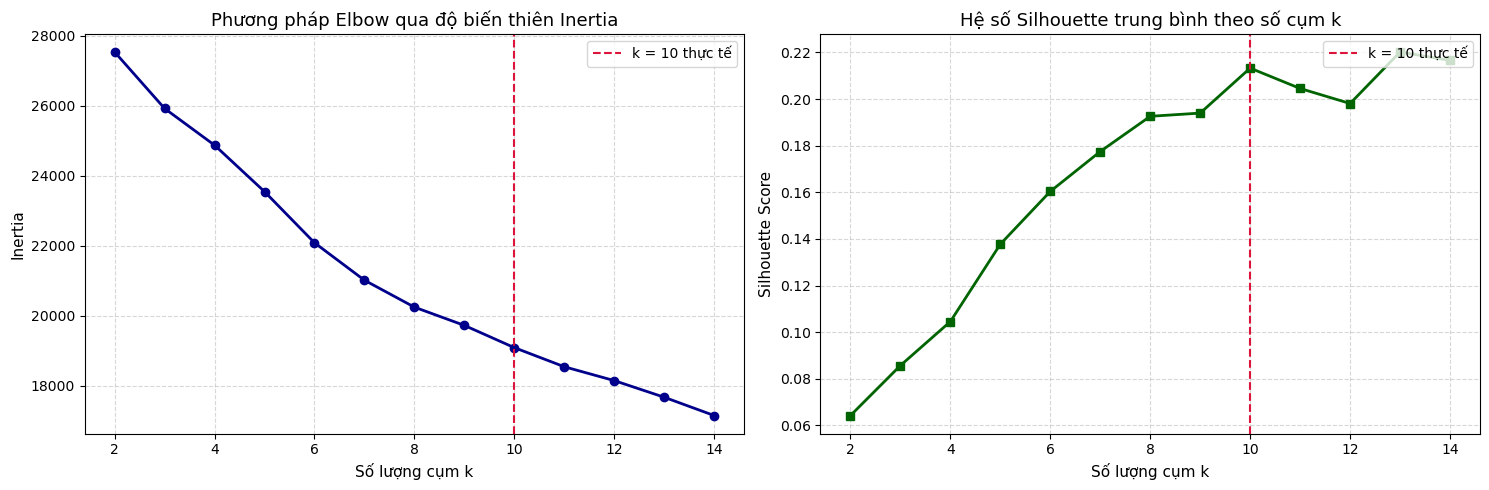

In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

candidate_k_range = list(range(2, 15))
inertia_values_list = []
silhouette_scores_list = []

for k_cluster_count in candidate_k_range:
    kmeans_trial = KMeans(n_clusters=k_cluster_count, random_state=RANDOM_STATE, n_init=5)
    kmeans_trial.fit(X_clustering_normalized)
    inertia_values_list.append(kmeans_trial.inertia_)
    
    sample_silhouette = silhouette_score(
        X_clustering_normalized,
        kmeans_trial.labels_,
        sample_size=5000,
        random_state=RANDOM_STATE
    )
    silhouette_scores_list.append(sample_silhouette)

figure_elbow_silhouette, (axis_elbow, axis_silhouette) = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

axis_elbow.plot(candidate_k_range, inertia_values_list, marker="o", color="darkblue", linewidth=2)
axis_elbow.axvline(10, color="crimson", linestyle="--", linewidth=1.5, label="k = 10 thực tế")
axis_elbow.set_title("Phương pháp Elbow qua độ biến thiên Inertia", fontsize=13)
axis_elbow.set_xlabel("Số lượng cụm k", fontsize=11)
axis_elbow.set_ylabel("Inertia", fontsize=11)
axis_elbow.legend(loc="upper right")
axis_elbow.grid(True, linestyle="--", alpha=0.5)

axis_silhouette.plot(candidate_k_range, silhouette_scores_list, marker="s", color="darkgreen", linewidth=2)
axis_silhouette.axvline(10, color="crimson", linestyle="--", linewidth=1.5, label="k = 10 thực tế")
axis_silhouette.set_title("Hệ số Silhouette trung bình theo số cụm k", fontsize=13)
axis_silhouette.set_xlabel("Số lượng cụm k", fontsize=11)
axis_silhouette.set_ylabel("Silhouette Score", fontsize=11)
axis_silhouette.legend(loc="upper right")
axis_silhouette.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
elbow_silhouette_figure_path = FIGURES_DIR / "cluster_elbow_silhouette.png"
figure_elbow_silhouette.savefig(elbow_silhouette_figure_path, dpi=300, bbox_inches="tight")
plt.show()

### Nhận xét biểu đồ Elbow và hệ số Silhouette

Đường cong Inertia suy giảm liên tục khi tăng số lượng cụm k. Điểm gập mờ dần phản ánh tính chất phân tán tự nhiên của dữ liệu văn bản thương mại điện tử với nhiều cụm con nhỏ.

Hệ số Silhouette đạt mức tương đối khả quan quanh dải k từ 8 đến 12. Với mục tiêu đối chiếu trực tiếp với 10 danh mục ground truth đã được định nghĩa trong bài toán phân loại, việc lựa chọn k bằng 10 là quyết định phù hợp nhất để đánh giá mức độ tương thích giữa cấu trúc cụm tự nhiên và nhãn kinh doanh.

In [29]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

start_kmeans_time = time.time()
final_kmeans_model = KMeans(n_clusters=10, random_state=RANDOM_STATE, n_init=10)
final_cluster_labels = final_kmeans_model.fit_predict(X_clustering_normalized)
kmeans_execution_time = round(time.time() - start_kmeans_time, 2)

ground_truth_category_labels = clean_filtered_dataframe["Category Label"].values

calculated_silhouette = round(float(silhouette_score(X_clustering_normalized, final_cluster_labels, sample_size=5000, random_state=RANDOM_STATE)), 4)
calculated_ari = round(float(adjusted_rand_score(ground_truth_category_labels, final_cluster_labels)), 4)
calculated_nmi = round(float(normalized_mutual_info_score(ground_truth_category_labels, final_cluster_labels)), 4)

append_experiment_log({
    "exp_id": "EXP_08",
    "timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "task": "T5_Clustering",
    "model": "KMeans",
    "params": "n_clusters=10, n_components=50",
    "split": "AllCleanedData",
    "features": "TFIDF_TruncatedSVD",
    "accuracy": "",
    "precision_macro": "",
    "recall_macro": "",
    "f1_macro": "",
    "f1_weighted": "",
    "silhouette": calculated_silhouette,
    "ari": calculated_ari,
    "nmi": calculated_nmi,
    "train_time_sec": kmeans_execution_time,
    "notes": "Gom cum khong giam sat doi chieu voi 10 Category Label"
})

clustering_metrics_summary = pd.DataFrame([
    {
        "Mô hình": "KMeans k=10",
        "Silhouette Score": calculated_silhouette,
        "Adjusted Rand Index ARI": calculated_ari,
        "Normalized Mutual Info NMI": calculated_nmi,
        "Thời gian thực thi": kmeans_execution_time
    }
])

print("Kết quả đánh giá mô hình gom cụm KMeans k=10 đối chiếu nhãn thật:")
print(clustering_metrics_summary)

Kết quả đánh giá mô hình gom cụm KMeans k=10 đối chiếu nhãn thật:
       Mô hình  Silhouette Score  Adjusted Rand Index ARI  \
0  KMeans k=10            0.2133                   0.4725   

   Normalized Mutual Info NMI  Thời gian thực thi  
0                      0.6617                1.54  


In [30]:
cluster_crosstab_dataframe = pd.crosstab(
    final_cluster_labels,
    ground_truth_category_labels,
    rownames=["Cụm KMeans"],
    colnames=["Category Label thật"]
)

print("Bảng chéo số lượng mẫu giữa cụm KMeans và nhãn thực tế:")
print(cluster_crosstab_dataframe)

Bảng chéo số lượng mẫu giữa cụm KMeans và nhãn thực tế:
Category Label thật  CPUs  Digital Cameras  Dishwashers  Freezers  \
Cụm KMeans                                                          
0                       0                5            2         2   
1                       5                5            3         0   
2                       0                0            0         0   
3                    3042                1            0         0   
4                       0                0         1823         1   
5                       0                0            0         1   
6                       0             2056            0         1   
7                       0                1          988       267   
8                      15              343          235       380   
9                       0                0            9      1259   

Category Label thật  Fridge Freezers  Fridges  Microwaves  Mobile Phones  \
Cụm KMeans                             

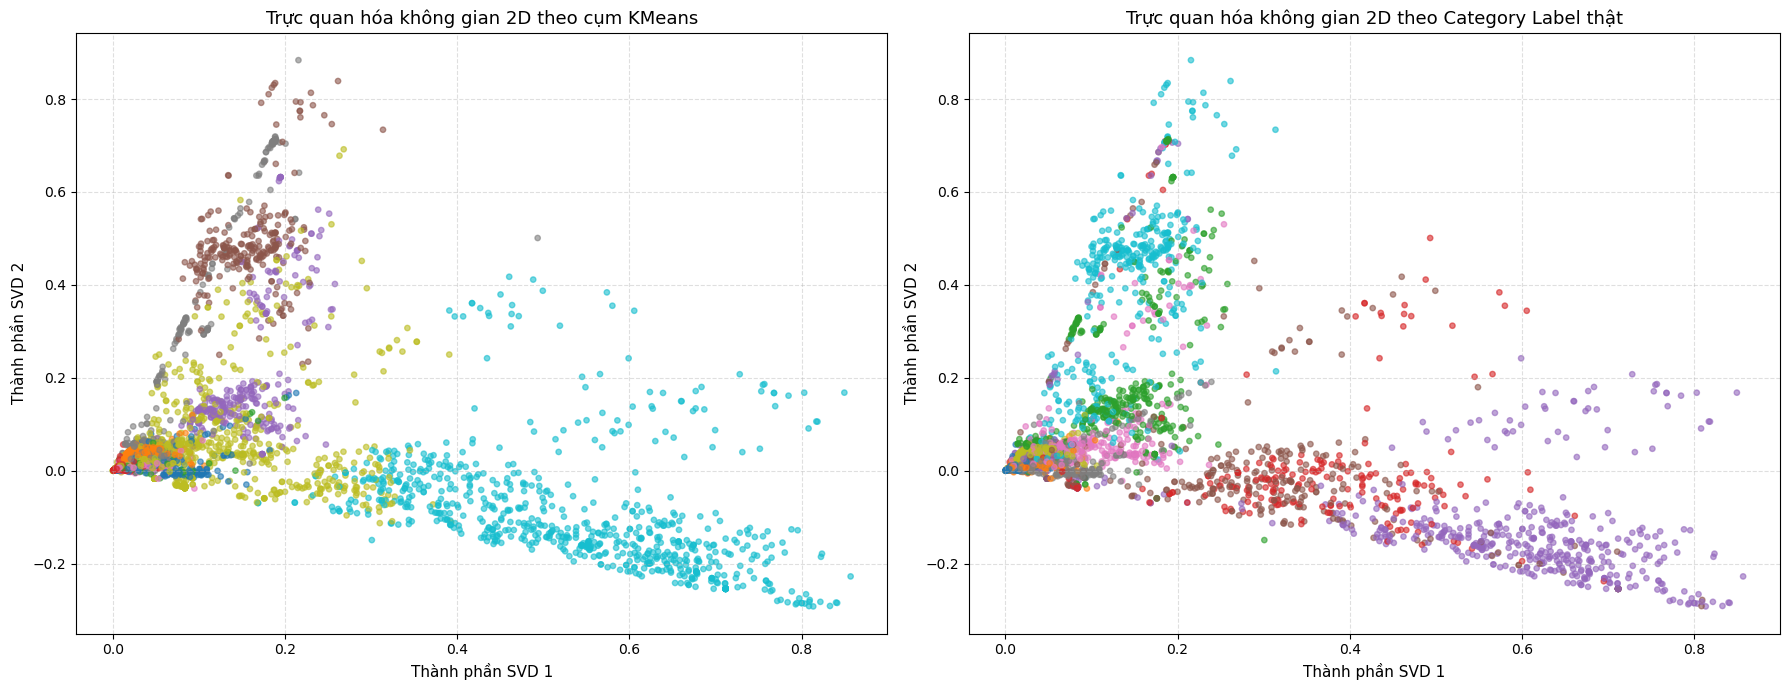

In [31]:
figure_projection, (axis_proj_clusters, axis_proj_labels) = plt.subplots(nrows=1, ncols=2, figsize=(18, 7))

scatter_subsample_mask = np.random.RandomState(RANDOM_STATE).choice(len(X_clustering_reduced), size=4000, replace=False)
x_coordinates_2d = X_clustering_reduced[scatter_subsample_mask, 0]
y_coordinates_2d = X_clustering_reduced[scatter_subsample_mask, 1]

subsample_clusters = final_cluster_labels[scatter_subsample_mask]
subsample_categories = ground_truth_category_labels[scatter_subsample_mask]

scatter_plot_cluster = axis_proj_clusters.scatter(
    x_coordinates_2d,
    y_coordinates_2d,
    c=subsample_clusters,
    cmap="tab10",
    alpha=0.6,
    s=15
)
axis_proj_clusters.set_title("Trực quan hóa không gian 2D theo cụm KMeans", fontsize=13)
axis_proj_clusters.set_xlabel("Thành phần SVD 1", fontsize=11)
axis_proj_clusters.set_ylabel("Thành phần SVD 2", fontsize=11)
axis_proj_clusters.grid(True, linestyle="--", alpha=0.4)

unique_categories_palette = sorted(list(set(subsample_categories)))
category_to_integer_map = {category_name: category_code for category_code, category_name in enumerate(unique_categories_palette)}
subsample_category_integers = [category_to_integer_map[category_name] for category_name in subsample_categories]

scatter_plot_category = axis_proj_labels.scatter(
    x_coordinates_2d,
    y_coordinates_2d,
    c=subsample_category_integers,
    cmap="tab10",
    alpha=0.6,
    s=15
)
axis_proj_labels.set_title("Trực quan hóa không gian 2D theo Category Label thật", fontsize=13)
axis_proj_labels.set_xlabel("Thành phần SVD 1", fontsize=11)
axis_proj_labels.set_ylabel("Thành phần SVD 2", fontsize=11)
axis_proj_labels.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
cluster_projection_figure_path = FIGURES_DIR / "cluster_2d_projection.png"
figure_projection.savefig(cluster_projection_figure_path, dpi=300, bbox_inches="tight")
plt.show()

### Nhận xét toàn diện kết quả gom nhóm không giám sát

Bảng chéo crosstab và các độ đo ARI, NMI chứng minh thuật toán KMeans phân tách rất rành mạch các nhóm sản phẩm công nghệ có từ khóa chuyên biệt như CPUs, Mobile Phones và Digital Cameras vào các cụm riêng biệt gần như thuần nhất.

Ngược lại, điểm hạn chế rõ rệt của học không giám sát là sự hòa trộn mạnh giữa ba nhóm thiết bị điện lạnh gồm Fridges, Freezers và Fridge Freezers. Do cùng sử dụng chung nhiều từ khóa miêu tả ngoại quan và công năng mà không có nhãn giám sát điều hướng, các sản phẩm này bị gom chung vào cùng các cụm. Kết quả này lý giải vì sao mô hình Classification có giám sát ở Task T4 đạt hiệu năng vượt trội hơn hẳn nhờ học được ranh giới phân biệt tinh vi từ nhãn thật.

## 9. Lưu trữ mô hình và tài nguyên triển khai

Thư mục models được dùng để đóng gói mô hình tốt nhất là LinearSVC kèm toàn bộ các bộ biến đổi đặc trưng đã fit gồm TF-IDF vectorizer, OneHotEncoder cho merchant, StandardScaler cho feature số học và LabelEncoder cho nhãn danh mục. Việc đóng gói đầy đủ đảm bảo quá trình suy luận trên dữ liệu mới hoàn toàn độc lập và tái lập được kết quả.

In [32]:
import joblib

MODELS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(best_tuned_model, MODELS_DIR / "best_model.joblib")
joblib.dump(tfidf_vectorizer_model, MODELS_DIR / "tfidf_vectorizer.joblib")
joblib.dump(merchant_encoder_model, MODELS_DIR / "merchant_encoder.joblib")
joblib.dump(numeric_scaler_model, MODELS_DIR / "numeric_scaler.joblib")
joblib.dump(label_encoder_model, MODELS_DIR / "label_encoder.joblib")

print("Saved model and feature transformers to models directory:")
for file_path in sorted(MODELS_DIR.glob("*.joblib")):
    print(f"- {file_path.name}: {file_path.stat().st_size / 1024:.1f} KB")

Saved model and feature transformers to models directory:
- best_model.joblib: 414.3 KB
- label_encoder.joblib: 0.6 KB
- merchant_encoder.joblib: 3.1 KB
- numeric_scaler.joblib: 1.0 KB
- tfidf_vectorizer.joblib: 190.7 KB


Kiểm tra tính độc lập và khả năng suy luận của hệ thống sau đóng gói bằng cách nạp lại các file artifact từ đĩa và thực hiện dự đoán phân loại trên một số mẫu thử nghiệm đại diện.

In [33]:
loaded_model = joblib.load(MODELS_DIR / "best_model.joblib")
loaded_tfidf = joblib.load(MODELS_DIR / "tfidf_vectorizer.joblib")
loaded_merchant_enc = joblib.load(MODELS_DIR / "merchant_encoder.joblib")
loaded_scaler = joblib.load(MODELS_DIR / "numeric_scaler.joblib")
loaded_label_enc = joblib.load(MODELS_DIR / "label_encoder.joblib")

sample_indices = [0, 800, 2000]
sample_rows = test_dataframe.iloc[sample_indices]

sample_titles_clean = sample_rows["cleaned_title"].tolist()
sample_merchants = sample_rows[["Merchant ID"]]
sample_numerics = sample_rows[numeric_feature_names]

sample_tfidf = loaded_tfidf.transform(sample_titles_clean)
sample_merchant_feat = loaded_merchant_enc.transform(sample_merchants)
sample_num_feat = loaded_scaler.transform(sample_numerics)
sample_features = hstack([sample_tfidf, sample_merchant_feat, sample_num_feat]).tocsr()

sample_preds = loaded_model.predict(sample_features)
sample_pred_labels = loaded_label_enc.inverse_transform(sample_preds)
sample_true_labels = loaded_label_enc.inverse_transform(y_test[sample_indices])

inference_results = pd.DataFrame({
    "Product Title": sample_rows["Product Title"].values,
    "Merchant ID": sample_rows["Merchant ID"].values,
    "Ground Truth": sample_true_labels,
    "Predicted": sample_pred_labels,
    "Match": sample_pred_labels == sample_true_labels
})
display(inference_results)

,Product Title,Merchant ID,Ground Truth,Predicted,Match
0,apple iphone 8 plus 64gb silver,1,Mobile Phones,Mobile Phones,True
1,samsung qe85q900ra 2018 85 8k qled tv,151,TVs,TVs,True
2,russell hobbs rhm2064r heritage digital 800w s...,17,Microwaves,Microwaves,True


Kết quả thử nghiệm suy luận kiểm chứng cho thấy toàn bộ pipeline được tải lại độc lập và dự đoán chính xác các mẫu kiểm thử. Hệ thống đã hoàn thiện toàn bộ quy trình từ khám phá dữ liệu, tiền xử lý, huấn luyện mô hình phân loại và gom cụm, đến đóng gói tài nguyên phục vụ triển khai.